<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:10px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">هفتهٔ ۱۲ | تعمیم‌پذیری و انتخاب مدل — نسخهٔ ساخت مستقل</strong><div><p>سه زنگ ۷۵ دقیقه‌ای: Overfitting/Validation، K-Fold از صفر و در نهایت <strong>ساخت صفر تا صد Pipeline + GridSearchCV + گزارش Test</strong>.

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(148,163,184,.32);border-right:5px solid #ea580c;border-radius:12px;background:rgba(234,88,12,.08);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#ea580c;margin-left:8px;"></span>تکمیل ریاضیات هفتهٔ ۱۲</div><div style="margin:0">در بخش‌های بعدی، توضیحات فرمول‌ها با مثال و استدلال بیشتر آمده است. این توضیحات جزو <b>جزوهٔ مفهومی</b> هستند و پاسخ تمرین‌های برنامه‌نویسی محسوب نمی‌شوند. تمرین‌های مستقل همچنان باید با کد کاملِ نوشته‌شده توسط خودتان حل شوند.</div></div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_SEED = 42
np.set_printoptions(precision=3, suppress=True)
print("Ready: NumPy, Pandas, Matplotlib, and scikit-learn.")

Ready: NumPy, Pandas, Matplotlib, and scikit-learn.


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p><code>numpy</code> برای آرایه‌ها و محاسبات، <code>pandas</code> برای جدول نتیجه، <code>matplotlib</code> برای نمایش، و <code>sklearn</code> برای مدل‌سازی است. <code>RANDOM_SEED</code> باعث می‌شود با اجرای دوباره نمونه‌ها قابل بازتولید باشند؛ به معنای از بین رفتن تصادفی بودن داده نیست.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:10px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em"> چرا مدل پیچیده‌تر الزاماً بهتر نیست؟</strong><div><p>هدف: مشاهدهٔ Overfitting و Underfitting با یک مسئلهٔ ثابت، شناخت Bias–Variance و فهم ضرورت Validation قبل از انتخاب مدل.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | یک مسئلهٔ غیرخطی اما کنترل‌شده</strong><div><p>برای اینکه خودمان پیچیدگی واقعی مسئله را بدانیم، ۷۵ مشاهده با یک تابع سینوسی و نویز می‌سازیم. نخست دادهٔ Test را کنار می‌گذاریم و به آن دست نمی‌زنیم؛ بعد از بقیهٔ داده‌ها Train و Validation می‌گیریم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 16px 10px;padding:18px 22px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.12em;margin:0 0 10px 0;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#0d9488;border-radius:50%;margin-left:8px;"></span>مدل تولید داده و تفاوت سیگنال با نویز</div><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">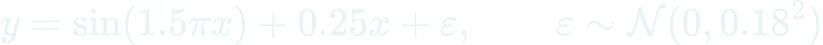</div>
<p style="margin:6px 0 10px;line-height:2.05;">در این آزمایش، تابع سینوسی «رابطهٔ اصلی» است و نویز باعث می‌شود نمونه‌ها
دقیقاً روی منحنی قرار نگیرند.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#0d9488;margin-left:8px;"></span>ریاضیات تکمیلی | سیگنال، نویز و مدل تولید داده</div><div style="margin:0">این داده‌ها «واقعی» نیستند؛ عمداً با یک قانون مشخص ساخته شده‌اند تا بتوانیم اثر پیچیدگی مدل را بدون حدس‌زدن دربارهٔ قانون اصلی بسنجیم. هر مشاهده از یک ورودی، یک مقدار تابع اصلی و یک نویز مستقل ساخته می‌شود. <b>نویز</b> جزئی از همان مشاهده است، نه خطایی که مدل بتواند همیشه دقیقاً پیش‌بینی کند.</div>
<p style="margin:6px 0 10px;line-height:2.05;">برای هر نمونهٔ مستقل با اندیس
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
داریم:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">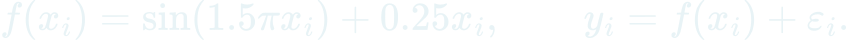</div>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \mathbb E[\varepsilon_i]=0,\qquad \mathrm{Var}(\varepsilon_i)=0.18^2,
\qquad \mathbb E[y_i\mid x_i]=f(x_i)." dir="ltr" src="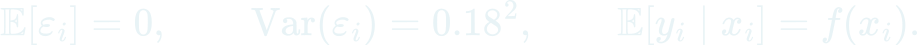" style="display:block;max-width:100%;width:418px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;"><strong>چرا این مهم است؟</strong> حتی اگر مدل دقیقاً
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;">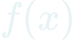</span>
را پیدا کند، نویز تصادفیِ
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
باقی می‌ماند. برای همین «خطای صفر روی دادهٔ جدید» هدف واقع‌بینانه‌ای نیست.
با زیادکردن درجهٔ مدل ممکن است به‌جای یادگرفتن
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>،
نویز نمونه‌های Train را دنبال کنیم.</p>
</div>

Train / Validation / Sealed Test: (90, 1) (30, 1) (30, 1)


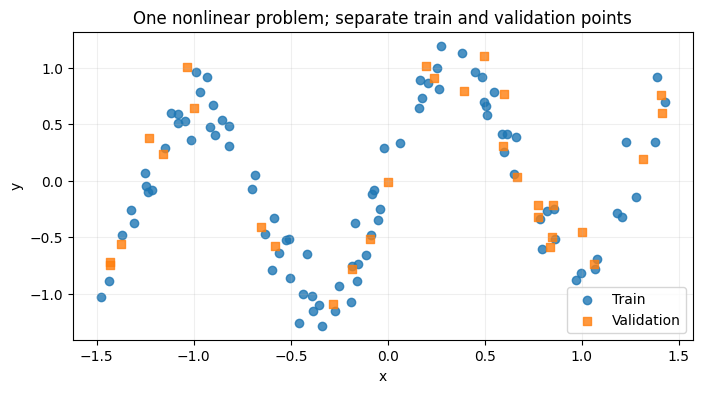

In [7]:
# Generate a small noisy nonlinear regression dataset.
rng = np.random.default_rng(RANDOM_SEED)
x_all = rng.uniform(-1.5, 1.5, size=150)
y_clean = np.sin(1.5 * np.pi * x_all) + 0.25 * x_all
y_all = y_clean + rng.normal(0.0, 0.18, size=len(x_all))
X_all = x_all.reshape(-1, 1)

# Seal the test set before model comparison and tuning.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=RANDOM_SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_SEED
)
print("Train / Validation / Sealed Test:", X_train.shape, X_val.shape, X_test.shape)
plt.figure(figsize=(8, 4))
plt.scatter(X_train[:, 0], y_train, label="Train", alpha=0.8)
plt.scatter(X_val[:, 0], y_val, label="Validation", marker="s", alpha=0.8)
plt.xlabel("x")
plt.ylabel("y")
plt.title("One nonlinear problem; separate train and validation points")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p><code>default_rng(42)</code> مولد اعداد تصادفی است. <code>reshape(-1, 1)</code> یک ویژگی را به ماتریس دوبعدی با یک ستون تبدیل می‌کند. دو فراخوانی <code>train_test_split</code> به‌ ترتیب Test و سپس Validation را جدا می‌کنند. در این بخش عمداً هیچ خطایی روی Test محاسبه نمی‌کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | سه مدل با ظرفیت متفاوت</strong><div><p>درجهٔ ۱ تنها یک خط، درجهٔ ۳ منحنی منعطف‌تر و درجهٔ ۱۵ یک چندجمله‌ای بسیار منعطف تولید می‌کند. هر سه را روی همان Train آموزش می‌دهیم و خطای Train/Validation را کنار نمودار می‌گذاریم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 16px 10px;padding:18px 22px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.12em;margin:0 0 10px 0;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#0d9488;border-radius:50%;margin-left:8px;"></span>توسعهٔ چندجمله‌ای و مفهوم ظرفیت</div><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">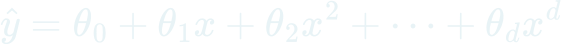</div>
<p style="margin:6px 0 10px;line-height:2.05;">با افزایش درجهٔ <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">d</code>، تعداد ضرایب و ظرفیت تابع برای خم شدن
بیشتر می‌شود؛ این الزاماً بهبود تعمیم نیست.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#0d9488;margin-left:8px;"></span>ریاضیات تکمیلی | چندجمله‌ای هنوز رگرسیون خطی است</div><div style="margin:0">«خطی بودن مدل» یعنی خطی بودن نسبت به <b>ضرایب</b>، نه لزوماً خطی بودن نسبت به ورودی. بعد از تبدیل ویژگی‌ها، همان رگرسیون کمترین مربعات را روی ستون‌های جدید اجرا می‌کنیم.</div>
<p style="margin:6px 0 10px;line-height:2.05;">اگر ورودی فقط یک ستون
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
داشته باشد، نگاشت درجهٔ سه را می‌توان این‌طور نوشت:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">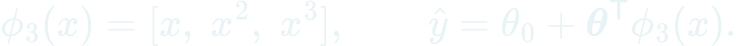</div>
<p style="margin:6px 0 10px;line-height:2.05;">برای
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
مشاهده، ماتریس ویژگی‌های درجهٔ
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
بدون ستون بایاس ابعاد
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
دارد. اگر جملهٔ ثابت با <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">LinearRegression(fit_intercept=True)</code>
جداگانه یاد گرفته شود، نیازی به ساخت ستون یک‌ها در
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">PolynomialFeatures</code> نیست.</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \underbrace{X}_{n\times1}\;\xrightarrow{\;\phi_d\;}\;
\underbrace{\Phi_d}_{n\times d}\;\xrightarrow{\;\text{Linear Regression}\;}\;\hat {\mathbf y}." dir="ltr" src="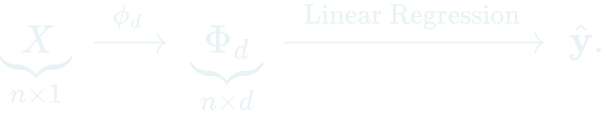" style="display:block;max-width:100%;width:275px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">برای <strong>دو</strong> ویژگی و درجهٔ دو، علاوه بر توان‌ها، جملهٔ
تعاملی نیز ساخته می‌شود:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">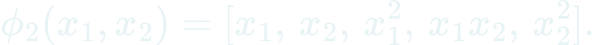</div>
<p style="margin:6px 0 10px;line-height:2.05;">شمار ویژگی‌های تولیدشده با
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
ویژگی و درجهٔ حداکثر
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>،
در حالت <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">include_bias=False</code> برابر است با:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">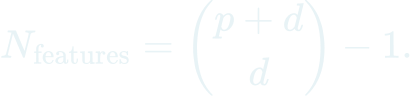</div>
<p style="margin:6px 0 10px;line-height:2.05;">پس افزایش درجه، تعداد ضرایب و انعطاف‌پذیری مدل را افزایش می‌دهد، ولی
تضمینی برای بهتر شدن روی داده‌های دیده‌نشده نیست.</p>
</div>

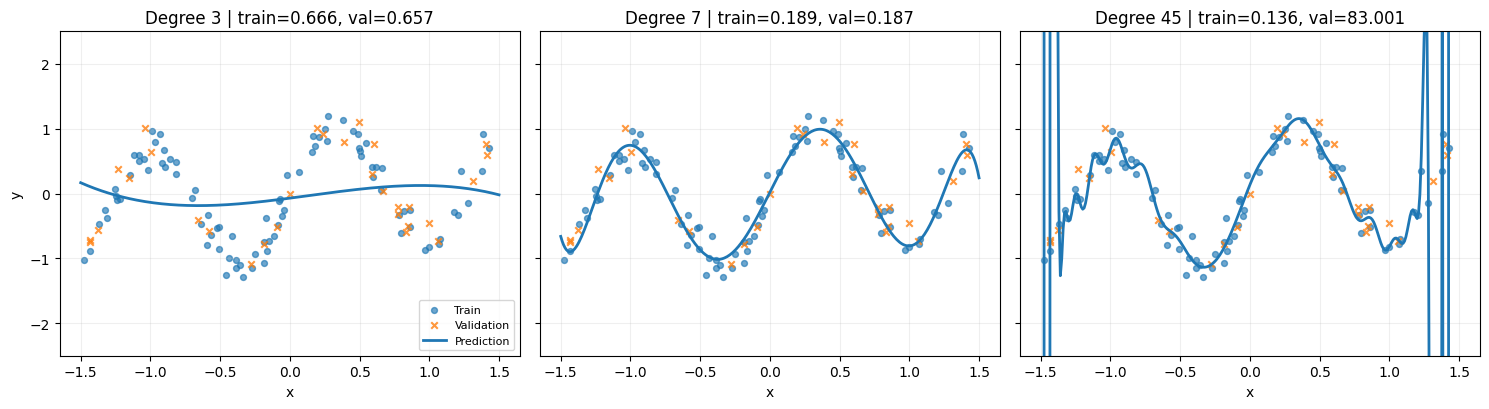

,Degree,Train RMSE,Validation RMSE
0,3,0.6663,0.6569
1,7,0.1891,0.1865
2,45,0.1365,83.0015


In [12]:
# Fit models with three different polynomial degrees.
def make_poly_model(degree):
    # Demo helper; the students will create a fully named Pipeline themselves in period 3.
    return make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )

plot_x = np.linspace(-1.5, 1.5, 300).reshape(-1, 1)
degree_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, degree in zip(axes, [3, 7, 45]):
    model = make_poly_model(degree)
    model.fit(X_train, y_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))
    val_rmse = np.sqrt(mean_squared_error(y_val, model.predict(X_val)))
    degree_rows.append({"Degree": degree, "Train RMSE": train_rmse, "Validation RMSE": val_rmse})
    ax.scatter(X_train[:, 0], y_train, s=18, label="Train", alpha=0.65)
    ax.scatter(X_val[:, 0], y_val, s=22, label="Validation", marker="x", alpha=0.8)
    ax.plot(plot_x[:, 0], model.predict(plot_x), linewidth=2, label="Prediction")
    ax.set_title(f"Degree {degree} | train={train_rmse:.3f}, val={val_rmse:.3f}")
    ax.set_xlabel("x")
    ax.set_ylim(-2.5, 2.5)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("y")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(degree_rows).round(4))

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p><code>make_poly_model</code> یک Pipeline تازه برای هر درجه می‌سازد تا حالت‌های آزمایش مستقل باشند. <code>fit</code> تنها با <code>X_train</code> انجام می‌شود؛ <code>predict</code> هم روی Train و هم Validation می‌رود. <code>sharey=True</code> مقیاس عمودی هر سه نمودار را ثابت نگه می‌دارد تا مقایسه گمراه‌کننده نباشد. <code>plot_x</code> فقط برای رسم منحنی صاف است؛ دادهٔ آموزشی نیست.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:10px;background:rgba(124,58,237,.11);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">سه وضعیت | Underfitting، مناسب، Overfitting</strong><div><p><strong>Underfitting (کم‌برازش):</strong> مدل ساده‌تر از الگوی اصلی است و حتی روی Train هم خوب عمل نمی‌کند؛ معمولاً خطای Train و Validation هر دو زیادند.</p><p><strong>Fit مناسب:</strong> الگوی مفید یاد گرفته می‌شود و خطای Validation نسبتاً کم می‌ماند.</p><p><strong>Overfitting (بیش‌برازش):</strong> مدل به جزئیات و نویز Train حساس می‌شود؛ خطای Train می‌تواند بسیار کم باشد، ولی Validation زیاد شود. صرفاً اختلاف خطا برای تشخیص کافی نیست؛ اندازهٔ مطلق خطا و شکل نمودار را هم ببینید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | Bias و Variance، بدون فرمول‌زدگی</strong><div><p>با چند بار عوض‌کردن نمونه‌های آموزشیِ تصادفی، مشاهده می‌کنیم مدل خیلی ساده معمولاً شکل مشابهی می‌سازد ولی الگوی اصلی را خوب نمی‌گیرد؛ مدل خیلی پیچیده ممکن است با عوض‌شدن داده خیلی متفاوت شود.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:10px;background:rgba(124,58,237,.11);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">تفاوت شهودی Bias و Variance</strong><div><p><strong>Bias (سوگیری مدل):</strong> خطای نظام‌مند ناشی از فرض‌های محدودکننده؛ مثلاً مجبورکردن یک رابطهٔ سینوسی به خط راست.</p><p><strong>Variance (واریانس مدل):</strong> حساسیت پیش‌بینی‌های مدل به تغییر مجموعهٔ آموزش. وقتی با عوض‌شدن چند نمونه، منحنیِ یادگرفته‌شده شدیداً عوض شود، Variance بالاست.</p><p><strong>دقت:</strong> واریانسِ این بحث با <code>np.var(y)</code> یکی نیست؛ دربارهٔ پراکندگی پیش‌بینی‌های <em>مدل‌های آموزش‌دیده روی نمونه‌های متفاوت</em> صحبت می‌کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 16px 10px;padding:18px 22px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.12em;margin:0 0 10px 0;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#0d9488;border-radius:50%;margin-left:8px;"></span>تجزیهٔ ایده‌آل خطای پیش‌بینی (در یک نقطهٔ ثابت)</div><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \mathbb E[(y-\hat f(x))^2]=\operatorname{Bias}[\hat f(x)]^2+\operatorname{Var}[\hat f(x)]+\sigma^2" dir="ltr" src="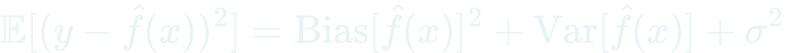" style="display:block;max-width:100%;width:357px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">این رابطه تحت فرض‌های معمول رگرسیون و نویزِ مستقل با میانگین صفر تفسیر
می‌شود. امروز فقط معنای سه جزء را می‌خواهیم، نه اثبات کامل.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 16px 10px;padding:18px 22px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.12em;margin:0 0 10px 0;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#0d9488;border-radius:50%;margin-left:8px;"></span>اثبات مرحله‌به‌مرحلهٔ رابطهٔ Bias–Variance–Noise</div><p style="margin:6px 0 10px;line-height:2.05;">در این قسمت، ورودی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">x</code> را ثابت می‌گیریم. اگر مجموعهٔ آموزشی
را عوض کنیم و مدل را دوباره آموزش بدهیم، پیش‌بینی مدل برای همین ورودی
ممکن است تغییر کند. همچنین مقدار واقعیِ مشاهدهٔ جدید دارای نویز است.</p>
<p style="margin:6px 0 10px;line-height:2.05;"><strong>فرض‌های مسئله:</strong> رابطهٔ واقعی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">f(x)</code> ثابت
است؛ دادهٔ جدید از مدل زیر به دست می‌آید و نویز آزمون از مجموعهٔ آموزشی
مستقل است:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">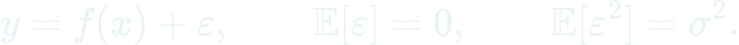</div>
<p style="margin:6px 0 10px;line-height:2.05;">اگر مدل آموزش‌دیده روی داده‌های تصادفی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">D</code> را با علامت زیر
نشان دهیم:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">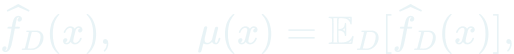</div>
<p style="margin:6px 0 10px;line-height:2.05;">تعریف بایاس و واریانس پیش‌بینی چنین است:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">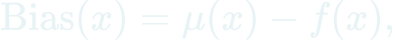</div>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">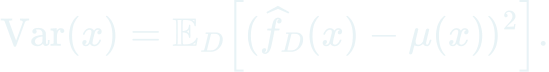</div>
<p style="margin:6px 0 10px;line-height:2.05;"><strong>قدم اول — خطا را به سه قسمت می‌شکنیم.</strong> یک بار
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">μ(x)</code> را کم و زیاد می‌کنیم:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \begin{aligned}
y-\widehat f_D(x)
&amp;=f(x)+\varepsilon-\widehat f_D(x)\\
&amp;=\underbrace{(f(x)-\mu(x))}_{A}
+\underbrace{(\mu(x)-\widehat f_D(x))}_{B}
+\underbrace{\varepsilon}_{C}.
\end{aligned}" dir="ltr" src="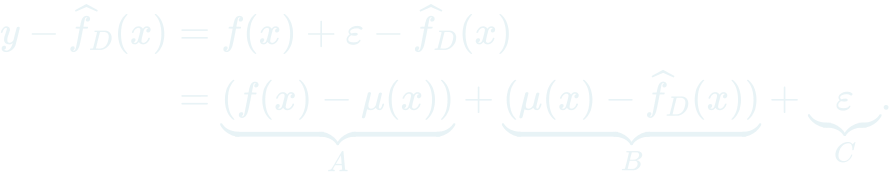" style="display:block;max-width:100%;width:405px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;"><strong>قدم دوم — مربع را باز می‌کنیم.</strong></p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">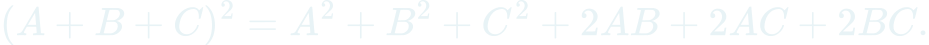</div>
<p style="margin:6px 0 10px;line-height:2.05;"><strong>قدم سوم — امید ریاضی می‌گیریم.</strong> چون <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">A</code> در
ورودی ثابت، عدد ثابتی است؛ میانگین <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">B</code> صفر است؛ میانگین
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">C</code> صفر است و نویز جدید از آموزش مستقل است، امید ریاضی هر سه
جملهٔ ضربی صفر می‌شود:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \mathbb E_D[B]=\mu-\mathbb E_D[\widehat f_D]=0,
\qquad \mathbb E[C]=0,
\qquad \mathbb E_{D,\varepsilon}[BC]=0." dir="ltr" src="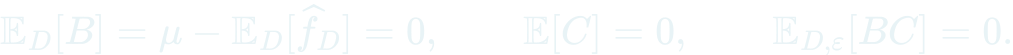" style="display:block;max-width:100%;width:460px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;"><strong>قدم چهارم — سه جملهٔ باقی‌مانده را می‌شناسیم.</strong></p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \begin{aligned}
\mathbb E[A^2] &amp;= (f-\mu)^2=\operatorname{Bias}(x)^2,\\
\mathbb E[B^2] &amp;= \operatorname{Var}(x),\\
\mathbb E[C^2] &amp;= \sigma^2.
\end{aligned}" dir="ltr" src="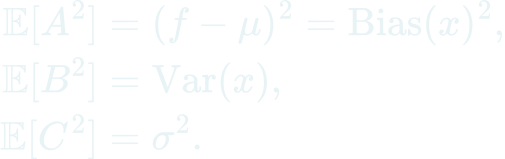" style="display:block;max-width:100%;width:230px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">بنابراین <strong>تجزیهٔ Bias–Variance–Noise</strong> چنین به دست
می‌آید:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \boxed{
\mathbb E_{D,\varepsilon}\!\left[(y-\widehat f_D(x))^2\right]
=\operatorname{Bias}(x)^2+\operatorname{Var}(x)+\sigma^2.
}" dir="ltr" src="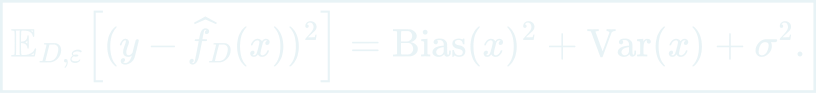" style="display:block;max-width:100%;width:371px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;"><strong>معنا:</strong> خطای میانگین از سه بخش می‌آید: فاصلهٔ میانگین
پیش‌بینی‌ها تا تابع واقعی (بایاس)، تغییر پیش‌بینی در تکرارهای آموزش
(واریانس) و نویز غیرقابل‌حذفِ مشاهدهٔ جدید. این یک رابطه برای <strong>خطای
مربعی مورد انتظار در یک ورودی ثابت</strong> است، نه خطای یک اجرای
خاص.</p></div>

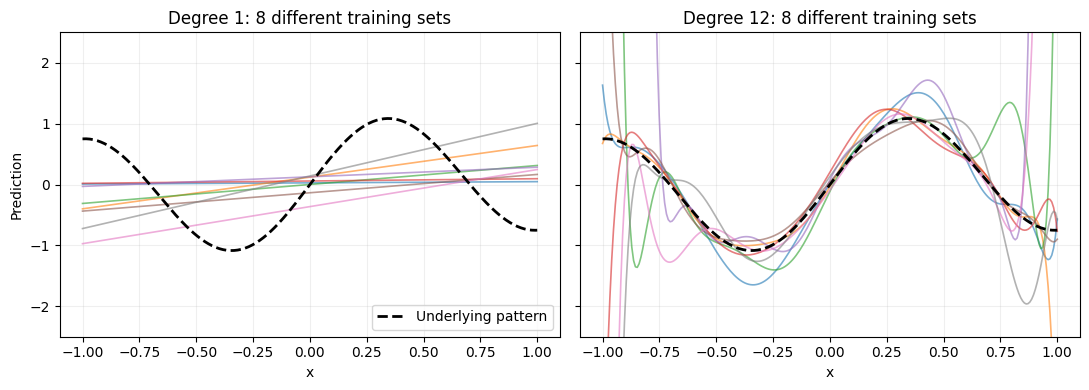

In [13]:
# Demonstrate sensitivity to training-sample changes.
rep_rng = np.random.default_rng(17)
fixed_grid = np.linspace(-1, 1, 250).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, degree in zip(axes, [1, 12]):
    for repetition in range(8):
        x_small = rep_rng.uniform(-1, 1, size=24).reshape(-1, 1)
        y_small = (np.sin(1.5 * np.pi * x_small[:, 0]) + 0.25 * x_small[:, 0]
                   + rep_rng.normal(0, 0.18, len(x_small)))
        candidate = make_poly_model(degree)
        candidate.fit(x_small, y_small)
        ax.plot(fixed_grid[:, 0], candidate.predict(fixed_grid), alpha=0.6, lw=1.2)
    ax.plot(fixed_grid[:, 0], np.sin(1.5 * np.pi * fixed_grid[:, 0])
            + 0.25 * fixed_grid[:, 0], "k--", lw=2, label="Underlying pattern")
    ax.set_title(f"Degree {degree}: 8 different training sets")
    ax.set_xlabel("x")
    ax.set_ylim(-2.5, 2.5)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Prediction")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p>هشت بار دادهٔ آموزشی جدید می‌سازیم و مدل را <strong>دوباره از صفر آموزش می‌دهیم</strong>. تفاوت خطوط روی یک شبکهٔ ثابت نشان‌دهندهٔ حساسیت مدل به تغییر داده است. محدودکردن <code>ylim</code> اجازه نمی‌دهد جهش‌های بسیار بزرگِ درجهٔ ۱۲ کل شکل را ناخوانا کنند؛ ممکن است بخشی از جهش‌ها خارج نمودار بیفتند.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | چرا به سه بخش داده نیاز داریم؟</strong><div><p>Train برای یادگرفتن ضرایب؛ Validation برای تصمیم بین مدل‌ها و ابرپارامترها؛ Test فقط برای گزارش عملکرد نهایی، پس از پایان تصمیم‌گیری.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:10px;background:rgba(124,58,237,.11);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">Train / Validation / Test و تفاوت پارامتر و ابرپارامتر</strong><div><p><strong>Train:</strong> پارامترهای درونیِ مدل (مثل ضرایب چندجمله‌ای) از این بخش یاد گرفته می‌شوند.</p><p><strong>Validation:</strong> با مقایسهٔ مدل‌هایی که روی Train آموزش دیده‌اند، ابرپارامترهایی مانند <code>degree</code> را انتخاب می‌کنیم.</p><p><strong>Test:</strong> برای تخمین نهایی عملکرد مدل منتخب روی دادهٔ جدید است؛ نباید از نتیجهٔ آن برای انتخاب مجدد درجه استفاده کنیم.</p><p><strong>نکته:</strong> هیچ نسبت تقسیم جادویی مثل ۶۰/۲۰/۲۰ برای همهٔ مسائل وجود ندارد. اندازهٔ داده، نوع مسئله و وابستگی زمانی/گروهی بر روش تقسیم اثر می‌گذارد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#0d9488;margin-left:8px;"></span>ریاضیات تکمیلی | Train / Validation / Test برای چه تصمیمی‌اند؟</div><div style="margin:0">ضرایب مدل با Train یاد گرفته می‌شوند، اما درجهٔ چندجمله‌ای یک ابرپارامتر است که باید پیش از آزمون نهایی انتخاب شود. مقایسهٔ چند مدل با یک Validation می‌تواند به انتخاب خوش‌بینانه روی همان Validation منجر شود؛ Cross-Validation این وابستگی را کاهش می‌دهد، ولی مجموعهٔ Test مستقل همچنان لازم است.</div>
<p style="margin:6px 0 10px;line-height:2.05;">به‌صورت نمادین، برای هر درجهٔ
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
ابتدا ضرایب را با کمینه‌کردن خطای Train به دست می‌آوریم:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \hat\theta_d=\operatorname*{argmin}_{\theta}\sum_{i\in\mathrm{Train}}
\big(y_i-\hat f_{d,\theta}(x_i)\big)^2." dir="ltr" src="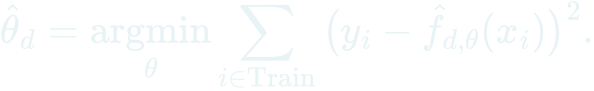" style="display:block;max-width:100%;width:270px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">سپس با خطای داده‌های Validation درجه را انتخاب می‌کنیم:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \hat d=\operatorname*{argmin}_{d\in\mathcal D}
\mathrm{RMSE}_{\mathrm{Validation}}\big(\hat f_{d,\hat\theta_d}\big)." dir="ltr" src="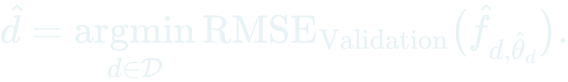" style="display:block;max-width:100%;width:258px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">اگر همان Validation را بارها برای تصمیم‌های مختلف ببینیم، احتمال
انتخابِ تصادفیِ مدل خوش‌شانس بیشتر می‌شود. به همین دلیل نمرهٔ نهایی Test را
پس از تثبیت کل فرایند گزارش می‌کنیم و دیگر براساس آن تنظیمات را عوض
نمی‌کنیم.</p>
</div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | Validation Curve | انتخاب درجهٔ چندجمله‌ای</strong><div><p>مدل‌های درجات ۱ تا ۱۵ را <em>همه</em> روی یک Train آموزش می‌دهیم، Train RMSE و Validation RMSE را ذخیره می‌کنیم و درجهٔ برنده را فقط با Validation انتخاب می‌کنیم.</p></div></div>

Best degree on this validation split: 9


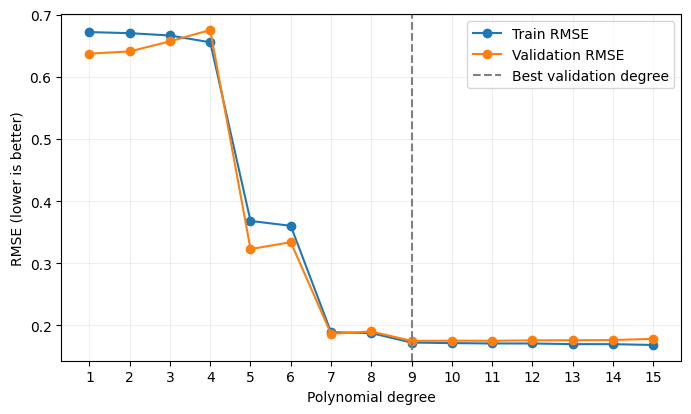

In [18]:
# Compare polynomial degrees without touching the test set.
degrees = np.arange(1, 16)
train_errors, val_errors = [], []
for degree in degrees:
    candidate = make_poly_model((degree))
    candidate.fit(X_train, y_train)
    train_errors.append(np.sqrt(mean_squared_error(y_train, candidate.predict(X_train))))
    val_errors.append(np.sqrt(mean_squared_error(y_val, candidate.predict(X_val))))

best_val_degree = (degrees[np.argmin(val_errors)])
print("Best degree on this validation split:", best_val_degree)
plt.figure(figsize=(8, 4.5))
plt.plot(degrees, train_errors, "o-", label="Train RMSE")
plt.plot(degrees, val_errors, "o-", label="Validation RMSE")
plt.axvline(best_val_degree, linestyle="--", color="gray", label="Best validation degree")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (lower is better)")
plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.2)
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p><code>np.argmin(val_errors)</code> <strong>اندیس</strong> کوچک‌ترین خطا را می‌دهد، نه مقدار درجه؛ پس با <code>degrees[...]</code> درجه را به دست می‌آوریم. <code>np.arange(1,16)</code> اعداد صحیح ۱ تا ۱۵ را تولید می‌کند. خطای Train برای شناخت رفتار مدل است؛ انتخاب نهایی در این زنگ با کمترین خطای Validation انجام می‌شود. از <code>X_test</code> هیچ استفاده‌ای نشده است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">فعالیت مستقل داخل کلاس 1 | انتخاب مدل روی دادهٔ Validation</strong><div><p><strong>برای حل این فعالیت، کد را کامل از صفر بنویسید.</strong> دو مدل درجهٔ ۲ و ۵ را روی <code>X_train</code> بسازید و مستقل Fit کنید. خطای Validation هر دو را در یک جدول دو‌ردیفی گزارش دهید و با <code>if</code> درجهٔ برنده را چاپ کنید. <strong>زمان پیشنهادی: ۷ دقیقه از پایان بخش Validation Curve.</strong></p><p>پاسخ را در سلول خالی بعد بنویسید. حل این فعالیت برای اجرای ادامهٔ نوت‌بوک الزامی نیست.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای فعالیت کلاسی ۱ | مقایسهٔ دو مدل</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">PolynomialFeatures</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">mean_squared_error</a><a dir="ltr" href="https://numpy.org/doc/stable/reference/generated/numpy.argmin.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">NumPy argmin</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">کد مقایسه، جدول و شرط انتخاب مدل را مستقل بنویسید؛ مستندات جای راه‌حل نیستند.</div></div>

In [23]:
# Write the complete code yourself.
preds = []
errors = []
my_rows = []
for deg in [2, 5]:
    model = make_poly_model(deg)
    model.fit(X_train, y_train)
    model.predict(X_val)
    error = np.sqrt(mean_squared_error(y_val , model.predict(X_val)))
    errors.append(error)
    my_rows.append((deg , error))
if errors[0] < errors[1]: 
    print(2)
else:
    print(5)

display(pd.DataFrame(my_rows, columns=["Degree", "Validation RMSE"]).round(4))


5


,Degree,Validation RMSE
0,2,0.6407
1,5,0.3228


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:10px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em"> K-Fold از صفر تا ابزارهای آماده</strong><div><p>هدف: دلیل نیاز به Cross-Validation، ساخت Foldهای بدون هم‌پوشانی، پیاده‌سازی دستی کامل، بررسی خروجی Scikit-Learn و تشخیص Data Leakage.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | کاغذ و تخته: ۲۰ شماره و پنج Fold</strong><div><p>ابتدا بدون کتابخانه، اعداد ۰ تا ۱۹ را به پنج مجموعهٔ چهارتایی تقسیم می‌کنیم؛ در هر دور یکی Validation می‌شود و چهار مجموعهٔ دیگر Train.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 16px 10px;padding:18px 22px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.12em;margin:0 0 10px 0;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#0d9488;border-radius:50%;margin-left:8px;"></span>اندازهٔ تقریبی هر Fold و میانگین خطا</div><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \text{Fold size}\approx \frac{n}{K},\qquad \overline{\mathrm{RMSE}}_{\mathrm{CV}}=\frac1K\sum_{k=1}^{K}\mathrm{RMSE}_k" dir="ltr" src="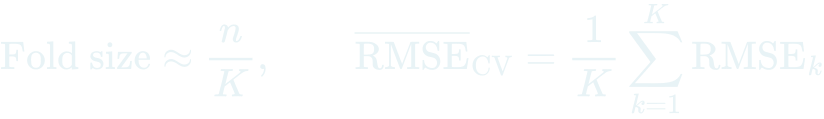" style="display:block;max-width:100%;width:375px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">اگر <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">n</code> بر <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">K</code> بخش‌پذیر نباشد، اندازهٔ بعضی
Foldها ممکن است یک نمونه تفاوت داشته باشد.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#0d9488;margin-left:8px;"></span>ریاضیات تکمیلی | چرا هر نمونه یک‌بار Validation می‌شود؟</div><div style="margin:0">فرض کنید مجموعهٔ توسعه را به <span dir="ltr" style="display:inline-block;unicode-bidi:isolate;font-family:inherit">K</span> قسمت <b>غیرهم‌پوشان</b> تقسیم کنیم. در دور <span dir="ltr" style="display:inline-block;unicode-bidi:isolate;font-family:inherit">k</span>، بخش <span dir="ltr" style="display:inline-block;unicode-bidi:isolate;font-family:inherit">Fₖ</span> برای اعتبارسنجی و بقیه برای آموزش استفاده می‌شود؛ در دور بعد این نقش جابه‌جا می‌شود.</div>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">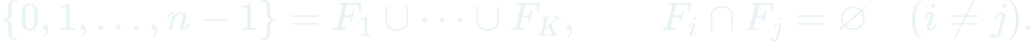</div>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">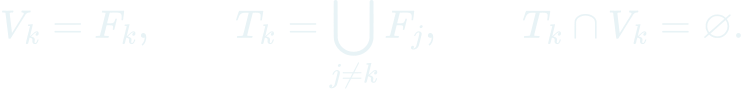</div>
<p style="margin:6px 0 10px;line-height:2.05;">برای ۲۰ نمونه و ۵ Fold، در هر دور ۴ داده برای Validation و ۱۶ داده
برای Train است. هر نمونه در مجموع یک‌بار در Validation و چهاربار در Train
حضور دارد. <strong>اما این به معنی استفادهٔ پیوسته از یک مدل
نیست:</strong> در هر دور، مدل باید دوباره از نو روی Train همان دور آموزش
داده شود.</p>
<p style="margin:6px 0 10px;line-height:2.05;">اگر
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
خطای RMSE روی Fold شمارهٔ
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
باشد، میانگین خطاهای Foldها را گزارش می‌کنیم:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">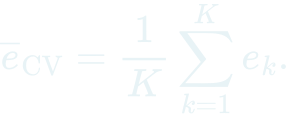</div>
<p style="margin:6px 0 10px;line-height:2.05;">دقت: میانگینِ RMSEهای Foldها لزوماً با RMSE حاصل از جمع‌کردن همهٔ خطاهای
پیش‌بینی Validation برابر نیست؛ به‌خصوص اگر اندازهٔ Foldها متفاوت
باشند.</p>
</div>

,Fold,Validation IDs,Train count,Validation count
0,1,"[0, 1, 2, 3]",16,4
1,2,"[4, 5, 6, 7]",16,4
2,3,"[8, 9, 10, 11]",16,4
3,4,"[12, 13, 14, 15]",16,4
4,5,"[16, 17, 18, 19]",16,4


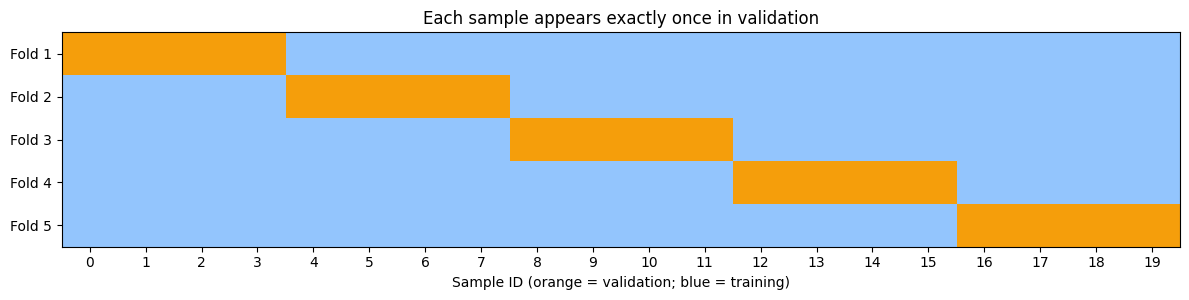

In [24]:
# Illustrate five-fold rotation for 20 fixed sample IDs.
ids = np.arange(20)
simple_folds = np.array_split(ids, 5)
fold_rows = []
for k, val_ids in enumerate(simple_folds, start=1):
    train_ids = np.concatenate([piece for j, piece in enumerate(simple_folds) if j != k - 1])
    fold_rows.append({"Fold": k, "Validation IDs": val_ids.tolist(),
                      "Train count": len(train_ids), "Validation count": len(val_ids)})
display(pd.DataFrame(fold_rows))

mask = np.ones((5, 20), dtype=int)
for k, val_ids in enumerate(simple_folds):
    mask[k, val_ids] = 0
fig, ax = plt.subplots(figsize=(12, 3.1))
from matplotlib.colors import ListedColormap
ax.imshow(mask, cmap=ListedColormap(["#f59e0b", "#93c5fd"]), aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(20))
ax.set_yticks(range(5), [f"Fold {k}" for k in range(1, 6)])
ax.set_xlabel("Sample ID (orange = validation; blue = training)")
ax.set_title("Each sample appears exactly once in validation")
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p><code>np.array_split</code> اندیس‌ها را به بخش‌هایی با اندازه نزدیک تقسیم می‌کند. <code>np.concatenate</code> بخش‌های غیر از Validation را به Train همان دور تبدیل می‌کند. تصویر با کدگذاری رنگی نشان می‌دهد هر ستون (نمونه) دقیقاً یک خانهٔ نارنجی دارد؛ یعنی هر نمونه دقیقاً یک بار Validation می‌شود.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | پیاده‌سازی K-Fold واقعاً از صفر</strong><div><p>اینجا از کلاس آمادهٔ <code>KFold</code> و تابع <code>cross_val_score</code> استفاده نمی‌کنیم؛ خودمان اندیس‌ها را درهم می‌ریزیم، Fold می‌سازیم و در هر دور یک مدل تازه آموزش می‌دهیم.</p></div></div>

In [25]:
# Manual 5-fold cross-validation: split indices, refit, validate, aggregate.
def manual_kfold_rmse(X, y, degree, n_splits=5, seed=123):
    X = np.asarray(X)
    y = np.asarray(y)
    rng_local = np.random.default_rng(seed)
    indices = rng_local.permutation(len(X))
    fold_indices = np.array_split(indices, n_splits)
    fold_errors = []
    predictions_count = np.zeros(len(X), dtype=int)

    for fold_number in range(n_splits):
        val_idx = fold_indices[fold_number]
        train_idx = np.concatenate([
            fold_indices[i] for i in range(n_splits) if i != fold_number
        ])
        fresh_model = make_poly_model(degree)
        fresh_model.fit(X[train_idx], y[train_idx])
        val_prediction = fresh_model.predict(X[val_idx])
        rmse = np.sqrt(mean_squared_error(y[val_idx], val_prediction))
        fold_errors.append(rmse)
        predictions_count[val_idx] += 1

    assert np.all(predictions_count == 1), "Each sample must be validated once."
    return np.array(fold_errors)

manual_scores = manual_kfold_rmse(X_trainval, y_trainval, degree=3, n_splits=5)
print("Manual validation RMSE per fold:", manual_scores.round(4))
print("Mean RMSE:", round(manual_scores.mean(), 4))
print("Std across folds:", round(manual_scores.std(ddof=0), 4))

Manual validation RMSE per fold: [0.584 0.639 0.716 0.749 0.702]
Mean RMSE: 0.6778
Std across folds: 0.0592


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p><code>permutation</code> فقط جای اندیس‌ها را تغییر می‌دهد؛ سطر و جواب هم‌زمان با اندیس یکسان انتخاب می‌شوند. <code>val_idx</code> شمارهٔ سطرهای اعتبارسنجی و <code>train_idx</code> مابقی سطرها هستند؛ با <code>X[train_idx]</code> و <code>y[train_idx]</code> برچسب‌ها هماهنگ می‌مانند. <code>fresh_model</code> باید داخل حلقه ساخته و Fit شود. <code>predictions_count</code> تضمین می‌کند در K-Fold معمولی، هیچ نمونه‌ای از Validation جا نمانده یا تکراری نشده است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 16px 10px;padding:18px 22px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.12em;margin:0 0 10px 0;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#0d9488;border-radius:50%;margin-left:8px;"></span>عدد CV و پراکندگی Foldها</div><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \overline e=\frac1K\sum_{k=1}^K e_k,\qquad s_{\mathrm{fold}}=\sqrt{\frac1K\sum_{k=1}^K(e_k-\overline e)^2}" dir="ltr" src="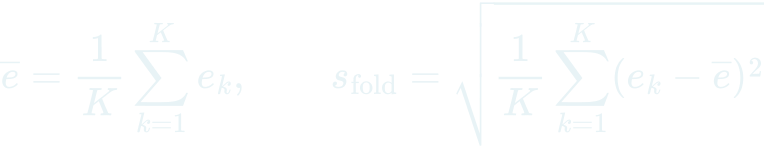" style="display:block;max-width:100%;width:347px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">اینجا <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">ddof=0</code> برای خلاصه‌کردن همین K امتیاز است. این
انحراف معیار را نباید بدون بررسی وابستگی Foldها به‌عنوان فاصلهٔ اطمینان
عملکرد مدل تعبیر کنیم.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#0d9488;margin-left:8px;"></span>ریاضیات تکمیلی | میانگین خوب، نوسان کم و تفاوت آن‌ها</div><div style="margin:0">میانگین خطا نشان می‌دهد مدل در این تقسیم‌بندی‌ها به‌طور متوسط چطور کار کرده؛ انحراف معیار نشان می‌دهد نمرهٔ Foldها چقدر با هم فرق داشته‌اند. <b>نوسان کم</b> به‌تنهایی به معنی خوب بودن مدل نیست؛ یک مدل بسیار ضعیف هم می‌تواند در تمام Foldها تقریباً یک اندازه بد باشد.</div>
<p style="margin:6px 0 10px;line-height:2.05;">برای خطاهای
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \bar e=\frac{1}{K}\sum_{k=1}^{K}e_k,\qquad
s_{\mathrm{fold}}=\sqrt{\frac1K\sum_{k=1}^{K}(e_k-\bar e)^2}." dir="ltr" src="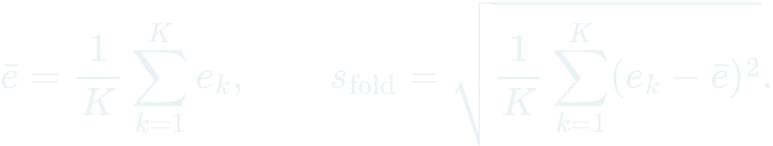" style="display:block;max-width:100%;width:351px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">اینجا
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
صرفاً برای <strong>توصیف پراکندگی همین K امتیازِ به‌دست‌آمده</strong>
استفاده می‌شود. Foldها مستقلِ آماری کامل نیستند، چون بخش زیادی از دادهٔ
Train آن‌ها مشترک است؛ بنابراین نباید
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
را بی‌احتیاط به‌عنوان عدم‌قطعیت دقیق عملکرد آینده تعبیر کرد.</p>
<p style="margin:6px 0 10px;line-height:2.05;"><strong>دقت در Scikit-Learn:</strong> نام
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">neg_root_mean_squared_error</code> علامت منفی دارد، چون ابزار
انتخاب مدل طوری طراحی شده که «امتیاز بزرگ‌تر بهتر است». بنابراین برای
گزارش RMSE معمول، علامت خروجی را برعکس می‌کنیم.</p>
</div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:10px;background:rgba(124,58,237,.11);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em"> نکات کلیدی در K-Fold</strong><div><p>۱) K یعنی تعداد Foldها، نه تعداد الگوریتم‌ها. ۲) هر نمونه دقیقاً یک بار در Validation می‌آید. ۳) در هر Fold مدل تازه‌ای آموزش داده می‌شود. ۴) در K-Fold معمولی Foldهای Validation هم‌پوشانی ندارند. ۵) مجموعه‌های Train در دورهای مختلف هم‌پوشانی زیادی دارند. ۶) Preprocessing یادگرفتنی باید <strong>داخل Fold</strong> Fit شود. ۷) Test نهایی هرگز در Foldهای انتخاب مدل قرار نمی‌گیرد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">فعالیت مستقل داخل کلاس 2 | مینی K-Fold فقط با NumPy</strong><div><p><strong>برای حل این فعالیت، کد را کامل از صفر بنویسید.</strong></p><p>برای اعداد ۰ تا ۱۱ با <code>np.array_split</code> سه Fold بسازید. در یک حلقه، اندیس‌های Train و Validation هر دور را چاپ کنید و در پایان تأیید کنید هر شناسه دقیقاً یک بار در Validation استفاده شده است. از <code>KFold</code> استفاده نکنید. <strong>زمان پیشنهادی: ۸ دقیقه از بازهٔ پیاده‌سازی دستی.</strong></p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای فعالیت کلاسی ۲ | K-Fold دستی با NumPy</div><div style="margin:3px 0;"><a dir="ltr" href="https://numpy.org/doc/stable/reference/generated/numpy.arange.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">NumPy arange</a><a dir="ltr" href="https://numpy.org/doc/stable/reference/generated/numpy.array_split.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">NumPy array_split</a><a dir="ltr" href="https://numpy.org/doc/stable/reference/generated/numpy.concatenate.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">NumPy concatenate</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">در این فعالیت استفاده از sklearn.model_selection.KFold ممنوع است؛ Foldها را خودتان بسازید.</div></div>

In [27]:
# Write the complete code yourself.
parts = np.array_split(np.arange(12), 3)

for i in range(3):
    val_part = parts[i]
    train_part = np.concatenate([parts[j] for j in range(3) if j != i])
    print(f"Fold {i + 1}: train : {train_part} , validation : {val_part}")

Fold 1: train : [ 4  5  6  7  8  9 10 11] , validation : [0 1 2 3]
Fold 2: train : [ 0  1  2  3  8  9 10 11] , validation : [4 5 6 7]
Fold 3: train : [0 1 2 3 4 5 6 7] , validation : [ 8  9 10 11]


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | Scikit-Learn: KFold و cross_val_score</strong><div><p>حالا با همان مجموعهٔ train+validation، شمارهٔ نمونه‌های هر Fold را از <code>KFold.split</code> می‌گیریم و امتیازهای یک Pipeline را با <code>cross_val_score</code> محاسبه می‌کنیم.</p></div></div>

In [28]:
# Inspect the fold indices created by scikit-learn.
cv = KFold(n_splits=5, shuffle=True, random_state=123)
for k, (tr_idx, va_idx) in enumerate(cv.split(X_trainval), start=1):
    print(f"Fold {k}: train={len(tr_idx)}, validation={len(va_idx)}, first validation IDs={va_idx[:4]}")

# Scikit-learn neg_root_mean_squared_error must be multiplied by -1.
cv_negative = cross_val_score(
    make_poly_model(3), X_trainval, y_trainval,
    cv=cv, scoring="neg_root_mean_squared_error"
)
cv_rmse = -cv_negative
print("sklearn validation RMSE per fold:", cv_rmse.round(4))
print("Mean RMSE:", round(cv_rmse.mean(), 4))
print("Manual vs sklearn, same scores up to fold ordering:",
      np.allclose(np.sort(manual_scores), np.sort(cv_rmse), atol=1e-10))

Fold 1: train=96, validation=24, first validation IDs=[0 4 5 8]
Fold 2: train=96, validation=24, first validation IDs=[ 9 19 21 23]
Fold 3: train=96, validation=24, first validation IDs=[ 1  6 11 12]
Fold 4: train=96, validation=24, first validation IDs=[ 2  3  7 10]
Fold 5: train=96, validation=24, first validation IDs=[17 25 32 36]
sklearn validation RMSE per fold: [0.654 0.641 0.675 0.725 0.689]
Mean RMSE: 0.6768
Manual vs sklearn, same scores up to fold ordering: False


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p><code>KFold(..., shuffle=True)</code> سطرها را تصادفی به Foldها تخصیص می‌دهد و <code>random_state</code> تقسیم را بازتولیدپذیر می‌کند. <code>cross_val_score</code> برای هر دور یک کپی تازه از مدل Fit می‌کند. نام <code>neg_root_mean_squared_error</code> منفی است، چون قرارداد این ابزار «امتیاز بزرگ‌تر بهتر» است؛ برای گزارش RMSE قابل‌فهم باید منفی آن را بگیریم. روش دستی با RNG NumPy و روش sklearn ترتیب تصادفی یکسانی ندارند؛ بنابراین <strong>لزومی ندارد امتیازهایشان برابر شوند</strong>؛ خط چاپی آخر هم ممکن است False باشد و این خطا نیست.</p></div></div>

In [31]:
# Verify exact manual-versus-library equality using identical fold assignments.
def get_manual_splits(n_samples, n_splits=5, seed=123):
    rng_check = np.random.default_rng(seed)
    ids_check = rng_check.permutation(n_samples)
    folds_check = np.array_split(ids_check, n_splits)
    return [
        (np.concatenate([folds_check[j] for j in range(n_splits) if j != i]), folds_check[i])
        for i in range(n_splits)
    ]

fixed_splits = get_manual_splits(len(X_trainval), n_splits=5, seed=123)
exact_scores = -cross_val_score(
    make_poly_model(3), X_trainval, y_trainval,
    cv=fixed_splits, scoring="neg_root_mean_squared_error"
)
print("Manual:", manual_scores.round(5))
print("Library on identical folds:", exact_scores.round(5))
print("They agree:", np.allclose(manual_scores, exact_scores))

Manual: [0.584 0.639 0.715 0.749 0.702]
Library on identical folds: [0.584 0.639 0.715 0.749 0.702]
They agree: True


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p>وقتی <code>cv</code> را به شکل فهرست زوج‌های اندیس Train/Validation تحویل می‌دهیم، sklearn همان تقسیم دستی را اجرا می‌کند. این تست، الگوریتم نمره‌دهی و جداسازی را بررسی می‌کند، بدون اینکه تصادفی‌سازی دو پیاده‌سازی را اشتباهاً یکسان فرض کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | چرا Foldها نمره‌های متفاوتی دارند؟</strong><div><p>مدل در هر دور مجموعهٔ آموزشی متفاوتی می‌بیند و روی نمونه‌های Validation متفاوتی ارزیابی می‌شود. با مقایسهٔ چند درجه می‌توانیم هم میانگین RMSE و هم نوسان آن را مشاهده کنیم.</p></div></div>

In [32]:
# Compare cross-validation scores for several polynomial degrees.
cv_summary = []
for degree in [1, 2, 3, 5, 9, 15]:
    scores = -cross_val_score(
        make_poly_model(degree), X_trainval, y_trainval,
        cv=KFold(n_splits=5, shuffle=True, random_state=123),
        scoring="neg_root_mean_squared_error"
    )
    cv_summary.append({"Degree": degree, "CV mean RMSE": scores.mean(),
                       "CV std RMSE": scores.std(ddof=0), "Fold RMSE": np.round(scores, 3).tolist()})
display(pd.DataFrame(cv_summary).round(4))

,Degree,CV mean RMSE,CV std RMSE,Fold RMSE
0,1,0.6708,0.0342,"[0.656, 0.618, 0.679, 0.724, 0.677]"
1,2,0.6744,0.0294,"[0.654, 0.637, 0.677, 0.724, 0.681]"
2,3,0.6768,0.0293,"[0.654, 0.641, 0.675, 0.725, 0.689]"
3,5,0.3694,0.0482,"[0.423, 0.38, 0.373, 0.392, 0.279]"
4,9,0.1864,0.0185,"[0.197, 0.151, 0.204, 0.187, 0.193]"
5,15,0.2015,0.0249,"[0.223, 0.156, 0.209, 0.223, 0.198]"


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p>برای منصفانه بودن مقایسه، در هر درجه یک نوع تقسیم Fold ثابت با همان تنظیمات استفاده می‌کنیم. <code>scores.mean()</code> خطای متوسط پنج دور را نشان می‌دهد و <code>std</code> اختلاف عملکرد روی Foldها را توصیف می‌کند. انحراف معیار کم به‌تنهایی دلیل بر خوب‌بودن مدل نیست؛ میانگین خطا هم مهم است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">پیش‌نمایش | Data Leakage در Cross-Validation</strong><div><p>اگر StandardScaler را پیش از Cross-Validation روی کل داده Fit کنیم، از Validation هر Fold برای تعیین آمار ویژگی‌ها استفاده کرده‌ایم؛ روش درست این است که مقیاس‌بندی داخل Pipeline باشد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #db2777;border-radius:10px;background:rgba(219,39,119,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">چرا پیش‌پردازش بیرون از Fold خطرناک است؟</strong><div><p>در هر دور CV، دادهٔ Validation باید از فرایند <strong>Fit</strong> آن دور کنار گذاشته شود. محاسبهٔ میانگین و انحراف معیار با همهٔ داده‌های train+validation، حتی بدون دیدن <code>y</code>، اطلاعات ویژگی‌های نمونهٔ Validation را وارد Fit کرده است.</p><p><strong>روش اشتباه:</strong> اول <code>StandardScaler().fit_transform(X_trainval)</code> و بعد Cross-Validation.</p><p><strong>روش درست:</strong> <code>Pipeline([("poly", ...), ("scaler", ...), ("model", ...)])</code> و سپردن Pipeline به CV؛ در هر Fold، هر مرحله روی Train همان Fold برازش می‌شود.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#0d9488;margin-left:8px;"></span>ریاضیات تکمیلی | چرا حتی میانگین X هم می‌تواند اطلاعات لو بدهد؟</div><div style="margin:0">ممکن است بپرسید «ما که به yهای Validation دست نزده‌ایم، پس Leakage کجاست؟». پاسخ این است که Scaler بیرونِ Fold، شکل توزیع Xهای Validation را هم دیده و از آن‌ها در میانگین و انحراف معیار استفاده کرده است؛ در حالی که در ارزیابی باید رفتاری شبیه ورود دادهٔ جدید داشته باشد.</div>
<p style="margin:6px 0 10px;line-height:2.05;">اگر در یک Fold تعداد نمونه‌های Train و Validation به‌ترتیب
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
و
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
باشند، میانگین اشتباهِ محاسبه‌شده روی هر دو بخش برابر است با:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">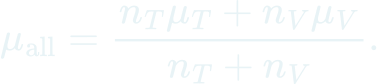</div>
<p style="margin:6px 0 10px;line-height:2.05;">اما میانگین مجاز برای مقیاس‌بندی همان Fold باید فقط
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
باشد:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: z_{i,j}^{(\mathrm{val})}=
\frac{x_{i,j}^{(\mathrm{val})}-\mu_{T,j}}{s_{T,j}},
\qquad
s_{T,j}^2=\frac1{n_T}\sum_{i\in T}(x_{i,j}-\mu_{T,j})^2." dir="ltr" src="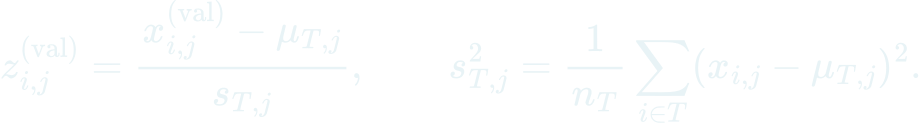" style="display:block;max-width:100%;width:419px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">پس حتی اگر اختلاف دو میانگین عددی کوچک باشد،
<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">fit_transform</code> کل داده قبل از K-Fold از نظر روش‌شناسی درست
نیست. این نکته برای Imputer، Feature Selector و PCA هم مهم است.</p>
</div>

In [33]:
# Compare statistics from all development data versus one training fold.
example_train_idx, example_val_idx = fixed_splits[0]
mean_all = X_trainval.mean(axis=0)
mean_fold_train = X_trainval[example_train_idx].mean(axis=0)
mean_fold_validation = X_trainval[example_val_idx].mean(axis=0)
print("Mean using all development rows:", mean_all.round(4))
print("Mean using this fold's train only:", mean_fold_train.round(4))
print("Mean of this fold's validation:", mean_fold_validation.round(4))
print("Difference (full - fold train):", (mean_all - mean_fold_train).round(4))

Mean using all development rows: [-0.067]
Mean using this fold's train only: [-0.069]
Mean of this fold's validation: [-0.057]
Difference (full - fold train): [0.003]


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p>در این مثال، فقط آمار یک ویژگی را چاپ می‌کنیم تا مفهوم لو رفتن آمار Validation دیده شود. <strong>این سلول برای نمایش خطای مفهومی است، نه توصیه به Fit کردن مدل با آمار اشتباه.</strong> اثر عددی leakage ممکن است در بعضی داده‌ها خیلی کم باشد و در بعضی مسائل شدید؛ اصل تقسیم درست به بزرگی اثر وابسته نیست.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #64748b;border-radius:10px;background:rgba(100,116,139,.07);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">استثناها | چه وقت KFold ساده کافی نیست؟</strong><div><p>اگر داده‌ها <strong>زمانی</strong> باشند، ترتیب آینده و گذشته را نمی‌توان با Shuffle نابود کرد (باید سراغ روش‌های زمانی رفت). اگر چند سطر متعلق به <strong>یک شخص/گروه</strong> باشند، نباید سطرهای همان شخص بین Train و Validation پخش شوند (مثل GroupKFold). برای کلاس‌بندی نامتوازن غالباً StratifiedKFold مناسب‌تر است.</p><p>امروز داده‌ها مستقل و مصنوعی‌اند، بنابراین KFold تصادفی مثال آموزشی مناسبی است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:10px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">  نوشتن کل Pipeline از صفر</strong><div><p>این زنگ، نمایش یک کد آماده نیست. چهار مرحله را روی همان دادهٔ هفته به هم وصل می‌کنیم: <strong>زنجیرهٔ دستی → Pipeline نام‌دار → انتخاب درجه با ۵-Fold → گزارش نهایی Test و Baseline</strong>.</p><p>متغیرهای <code>X_train, X_val, X_trainval, X_test</code> از جلسات قبل آماده‌اند؛ <strong>ساخت مدل و ارزیابی از صفر بر عهدهٔ شماست</strong>.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:10px;background:rgba(124,58,237,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">نقشهٔ مسیر | چه چیزهایی باید نوشته شوند؟</strong><div><p>مرحلهٔ اول: <code>PolynomialFeatures</code> و سپس <code>StandardScaler</code> هر دو فقط از دادهٔ آموزشی Fit می‌شوند؛ بعد <code>LinearRegression</code> Fit می‌شود.</p><p>مرحلهٔ دوم: سه مرحله در <code>Pipeline</code> قرار می‌گیرند. نام مرحلهٔ اول حتماً <code>poly</code> باشد تا <code>poly__degree</code> قابل جست‌وجو شود.</p><p>مرحلهٔ سوم: در ۵ Fold، برای هر درجه یک Pipeline تازه داخل هر Fold Fit می‌شود. مقدار <code>scoring</code> منفی است تا Scikit-Learn بتواند آن را بیشینه کند.</p><p>مرحلهٔ چهارم: بعد از انتخاب بهترین درجه، بهترین مدل روی دادهٔ توسعه Fit شده است؛ روی Test فقط <code>predict</code> می‌کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">کارگاه کلاسی الف | زنجیرهٔ دستی بدون Pipeline (از صفر)</strong><div><p>اول خودتان تک‌تک مراحل را بنویسید. بدون استفاده از <code>Pipeline</code> و <code>make_poly_model</code>، روی <code>X_train, y_train</code> مراحل زیر را اجرا کنید:</p><p>۱) <code>PolynomialFeatures(degree=3, include_bias=False)</code> بسازید؛ روی Train با <code>fit_transform</code> و روی Validation فقط با <code>transform</code> ویژگی تولید کنید. ۲) یک <code>StandardScaler</code> بسازید؛ آماره‌ها را فقط روی Train بگیرید. ۳) یک <code>LinearRegression</code> جدید Fit کنید و <code>validation RMSE</code> را محاسبه کنید.</p><p><strong>خروجی:</strong> شکل داده بعد از تبدیل، میانگین ستون‌های Train بعد از استانداردسازی، و RMSE. <strong>سؤال:</strong> چرا در Validation از <code>fit_transform</code> استفاده نمی‌کنیم؟</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای کارگاه الف | زنجیرهٔ دستی بدون Pipeline</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">PolynomialFeatures</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">StandardScaler</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">LinearRegression</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">استفاده از سه ابزار معرفی‌شده مجاز است، اما اتصال مراحل و ارزیابی را بدون کلاس Pipeline بنویسید.</div></div>

In [ ]:
# Write the complete solution here yourself.  TODO
poly_features = PolynomialFeatures(degree=3, include_bias=False)
poly_features_train = poly_features.fit_transform(X_train)
poly_features_val = poly_features.transform(X_val)

scaler =  StandardScaler()
train_scaled =  scaler.fit_transform(poly_features_train)
val_scaled = scaler.transform(poly_features_val)

regressor = LinearRegression()
regressor.fit(train_scaled , y_train)
val_pred = regressor.predict(val_scaled)
rmse = np.sqrt(mean_squared_error(y_val, val_pred))

print(train_scaled.mean(axis=0))
print()

[ 0. -0.  0.]
0.6569277442100373


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 16px 10px;padding:18px 22px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.12em;margin:0 0 10px 0;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#0d9488;border-radius:50%;margin-left:8px;"></span>یادآوری رابطهٔ تبدیل ویژگی و ارزیابی</div><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: x\longrightarrow [x,x^2,x^3]\longrightarrow z\longrightarrow \hat y,\qquad \mathrm{RMSE}=\sqrt{\frac1n\sum_i(y_i-\hat y_i)^2}" dir="ltr" src="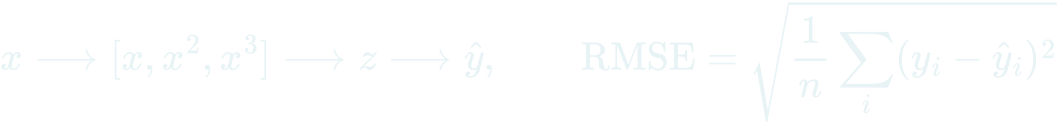" style="display:block;max-width:100%;width:480px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#0d9488;margin-left:8px;"></span>ریاضیات تکمیلی | زنجیرهٔ سه مرحله‌ای دقیقاً چه می‌کند؟</div><div style="margin:0">داده در هر مرحله شکل و معنای متفاوتی پیدا می‌کند: اول ستون‌های غیرخطی جدید تولید می‌شوند؛ بعد برای هر ستون با آمار Train مقیاس‌بندی می‌شود؛ سپس یک مدل خطی نسبت به ضرایب، خروجی را پیش‌بینی می‌کند.</div>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \Phi_d=\operatorname{Poly}_d(X),\qquad
\mu_j=\frac1{n_{\mathrm{train}}}\sum_{i\in\mathrm{Train}}\Phi_{ij}," dir="ltr" src="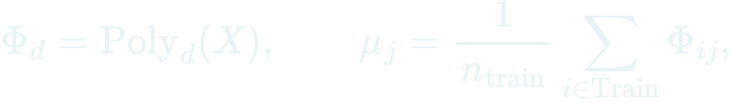" style="display:block;max-width:100%;width:332px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \sigma_j=\sqrt{\frac1{n_{\mathrm{train}}}\sum_{i\in\mathrm{Train}}(\Phi_{ij}-\mu_j)^2},\qquad
Z_{ij}=\frac{\Phi_{ij}-\mu_j}{\sigma_j}." dir="ltr" src="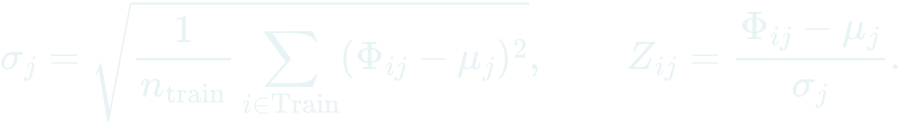" style="display:block;max-width:100%;width:410px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">اگر ستونی انحراف معیار صفر داشته باشد، برای جلوگیری از تقسیم بر صفر،
مقیاس آن را ۱ در نظر می‌گیریم. سپس:</p>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \hat{\mathbf y}=Z\boldsymbol\theta+\theta_0\mathbf 1,
\qquad\mathrm{RMSE}=\sqrt{\frac1m\sum_{i=1}^{m}(y_i-\hat y_i)^2}." dir="ltr" src="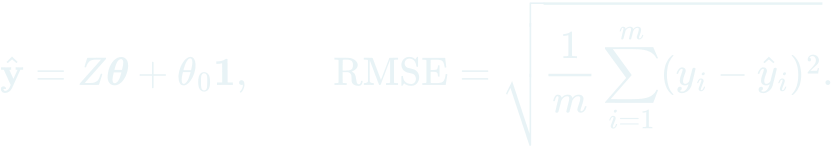" style="display:block;max-width:100%;width:379px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;"><strong>قانون حیاتی:</strong> در هر Fold،
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
و
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
را فقط از Train همان Fold پیدا می‌کنیم و بدون محاسبهٔ دوباره روی
Validation اعمال می‌کنیم. بازبرازش روی Validation، ارزیابی را آلوده
می‌کند.</p>
</div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">کارگاه کلاسی ب | تبدیل همان مراحل به یک Pipeline کامل</strong><div><p>حالا بدون کپی‌کردن کد آماده و بدون استفاده از تابع <code>make_poly_model</code>، شیئی به نام <code>student_pipeline</code> بسازید. سه مرحله باید به‌ترتیب <code>poly</code>، <code>scaler</code> و <code>regressor</code> نام داشته باشند. درجهٔ چندجمله‌ای را ۳ قرار دهید.</p><p>آن را فقط روی <code>X_train, y_train</code> برازش کنید، روی <code>X_val</code> پیش‌بینی بگیرید و RMSE را حساب کنید. سپس با <code>np.allclose</code> تأیید کنید پیش‌بینی‌های Pipeline با زنجیرهٔ دستی قسمت «الف» یکسان‌اند.</p><p><strong>خروجی:</strong> اسامی مراحل، RMSE و نتیجهٔ مقایسه. </div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای کارگاه ب | ساخت Pipeline </div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Pipeline</a><a dir="ltr" href="https://numpy.org/doc/stable/reference/generated/numpy.allclose.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">NumPy allclose</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Regression Metrics</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">از سلول خالی شروع کنید؛ نام مراحل، Fit، Predict و مقایسهٔ دو مسیر را خودتان طراحی کنید.</div></div>

In [ ]:
# Write the complete solution here yourself.TODO

pipline = Pipeline([
    ('poly_features' , PolynomialFeatures(degree=3, include_bias=False)),
    ('scaler' , StandardScaler()), 
    ('regressor', LinearRegression())
])

pipline.fit(X_train, y_train)
pipline_val_predict = pipline.predict(X_val)
pipline_val_rmse = np.sqrt(mean_squared_error(y_val, pipline_val_predict))

print(pipline.named_steps)
print(np.allclose(val_pred ,pipline_val_predict ))

{'poly_features': PolynomialFeatures(degree=3, include_bias=False), 'scaler': StandardScaler(), 'regressor': LinearRegression()}
True


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">کارگاه کلاسی ج | اتصال Pipeline به GridSearchCV و K-Fold</strong><div><p>از همان <code>student_pipeline</code> استفاده کنید؛ هرگز با دادهٔ Test درجه را انتخاب نکنید. یک <code>param_grid</code> برای درجات <code>[1, 2, 3, 4, 5, 7, 9, 12, 15]</code> بسازید؛ توجه کنید نام پارامتر باید <code>poly__degree</code> باشد.</p><p>یک <code>GridSearchCV</code> با ۵-Fold، <code>shuffle=True</code>، <code>random_state=123</code> و معیار <code>neg_root_mean_squared_error</code> تعریف کنید. روی <code>X_trainval, y_trainval</code> Fit کنید، بهترین درجه و CV RMSE را چاپ کنید؛ از خروجی <code>cv_results_</code> جدول رتبهٔ درجات را بسازید.</p><p><strong>توضیح مکتوب:</strong> چرا امتیاز <code>mean_test_score</code> همان Test نهایی نیست؟ چرا Fit کردن Scaler درون Pipeline از نشت اطلاعات جلوگیری می‌کند؟</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای کارگاه ج | GridSearchCV و انتخاب درجه</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">GridSearchCV</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">KFold</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-parameter" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Scoring in Scikit-Learn</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">مجموعهٔ Test نهایی برای انتخاب درجه ممنوع است؛ ساخت پارامترها و جدول نتایج با خودتان.</div></div>

In [49]:
# Write the complete solution here yourself. TODO

parameter_grid = {'poly_features__degree' : [1, 2, 3, 4, 5, 6, 7 ,8 ,9 , 12 , 15]}
search = GridSearchCV(
    estimator=pipline,
    param_grid=parameter_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=123),
    scoring='neg_root_mean_squared_error',
    refit = True,
    n_jobs = 1
)
search.fit(X_trainval, y_trainval)

print(search.best_params_)
print(-search.best_score_)
# search.cv_results_
ranking = pd.DataFrame(search.cv_results_)[['param_poly_features__degree', 'mean_test_score', 'rank_test_score']]
ranking['CV RMSE'] = -ranking['mean_test_score']
ranking = ranking.sort_values('CV RMSE')
ranking

{'poly_features__degree': 9}
0.18644674787606394


,param_poly_features__degree,mean_test_score,rank_test_score,CV RMSE
8,9,-0.186447,1,0.186447
9,12,-0.200463,2,0.200463
10,15,-0.201548,3,0.201548
6,7,-0.202487,4,0.202487
7,8,-0.205009,5,0.205009
5,6,-0.368721,6,0.368721
4,5,-0.369431,7,0.369431
0,1,-0.670765,8,0.670765
1,2,-0.674407,9,0.674407
2,3,-0.676818,10,0.676818


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 16px 10px;padding:18px 22px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.12em;margin:0 0 10px 0;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#0d9488;border-radius:50%;margin-left:8px;"></span>انتخاب درجه با میانگین خطای Foldها</div><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">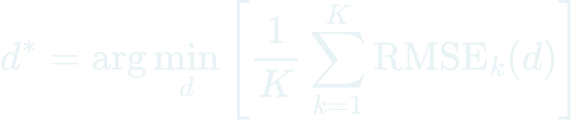</div>
<p style="margin:6px 0 10px;line-height:2.05;">ارزیابی روی Test فقط بعد از این مرحله انجام می‌شود.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#0d9488;margin-left:8px;"></span>ریاضیات تکمیلی | منظور از argmin و انتخاب ابرپارامتر چیست؟</div><div style="margin:0"><span dir="ltr" style="display:inline-block;unicode-bidi:isolate;font-family:inherit">argmin</span> خودِ مقداری را برمی‌گرداند که تابع هدف برای آن کمینه شده است؛ اینجا خروجی «درجهٔ چندجمله‌ای» است، نه مقدار خطا. برای هر درجه <span dir="ltr" style="display:inline-block;unicode-bidi:isolate;font-family:inherit">d</span>، تمام Foldها باید آموزش و اعتبارسنجی شوند.</div>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \widehat d=\underset{d\in\mathcal D}{\operatorname{argmin}}\;\frac1K
\sum_{k=1}^{K}\sqrt{\frac1{|V_k|}\sum_{i\in V_k}\big(y_i-\hat f_{d,k}(x_i)\big)^2}." dir="ltr" src="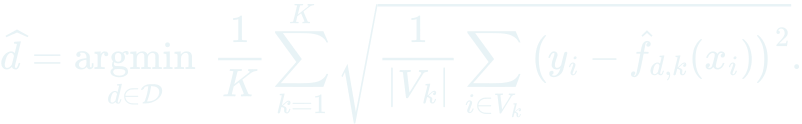" style="display:block;max-width:100%;width:365px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<p style="margin:6px 0 10px;line-height:2.05;">در این فرمول،
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;">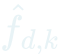</span>
مدلی است که <strong>برای درجهٔ
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>
و روی Train همان Fold شمارهٔ
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span></strong>
برازش شده است؛ پس اگر ۹ درجه و ۵ Fold داریم، دست‌کم ۴۵ بار فرایند برازش
در مرحلهٔ جست‌وجو تکرار می‌شود.</p>
<p style="margin:6px 0 10px;line-height:2.05;">پس از یافتن
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;"></span>،
با <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">refit=True</code> مدل برگزیده روی <strong>تمام دادهٔ
توسعه</strong> دوباره آموزش می‌بیند. تازه بعد از این مرحله، Test جداشده
را برای گزارش نهایی باز می‌کنیم.</p>
</div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">کارگاه کلاسی د | ارزیابی نهایی و مقایسه با DummyRegressor</strong><div><p>تنها بعد از پایان بخش «ج» از Test استفاده کنید. از <code>search.best_estimator_</code> پیش‌بینی Test بگیرید؛ <code>RMSE</code> و <code>R²</code> را حساب کنید. سپس <code>DummyRegressor(strategy="mean")</code> را فقط روی دادهٔ توسعه Fit کنید و معیارهای همان Test را محاسبه کنید.</p><p><strong>خروجی:</strong> یک جدول مقایسهٔ دو مدل، نمودار منحنی نهایی روی داده‌ها، و دو جمله تحلیل. بعد از مشاهدهٔ Test دیگر درجه را تغییر ندهید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:16px 20px;border:1px solid rgba(13,148,136,.40);border-right:5px solid #0d9488;border-radius:12px;background:rgba(13,148,136,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:break-word;line-height:2.05;color:inherit;"><div style="font-weight:750;font-size:1.08em;margin:0 0 8px 0;"><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#0d9488;margin-left:8px;"></span>ریاضیات تکمیلی | Baseline، RMSE و ضریب تعیین R²</div><div style="margin:0">مدل مبنا باید معیار مقایسهٔ قابل‌فهمی ارائه دهد. `DummyRegressor(strategy="mean")` هنگام Fit میانگین هدف‌های Train را حفظ می‌کند؛ برای هر ورودی جدید همان مقدار ثابت را پیش‌بینی می‌کند. گزارش R² باید با مقادیر واقعی همان مجموعهٔ ارزیابی محاسبه شود.</div>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;"><img alt="فرمول ریاضی: \mathrm{SSE}=\sum_{i=1}^{m}(y_i-\hat y_i)^2,\qquad
\mathrm{SST}=\sum_{i=1}^{m}(y_i-\bar y_{\mathrm{eval}})^2." dir="ltr" src="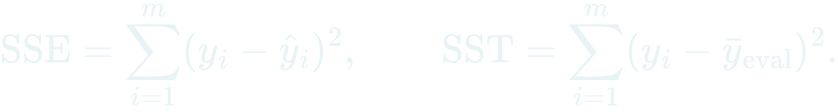" style="display:block;max-width:100%;width:381px;height:auto;margin:3px auto;object-fit:contain;" title="فرمول ریاضی (نسخهٔ تعبیه‌شده برای Jupyter و VS Code)"/></div>
<div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;white-space:nowrap;margin:13px 0;padding:13px 8px;border:1px solid rgba(13,148,136,.20);background:rgba(13,148,136,.05);border-radius:9px;line-height:1.45;">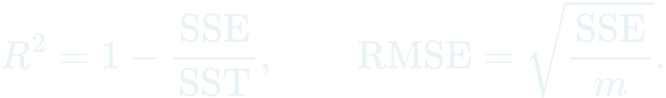</div>
<p style="margin:6px 0 10px;line-height:2.05;">اگر
<span dir="ltr" style="display:inline-block;direction:ltr;unicode-bidi:isolate;vertical-align:middle;white-space:nowrap;">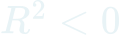</span>،
پیش‌بینی‌های مدل از پیش‌بینی ثابتِ <b>میانگین هدف‌های مجموعهٔ ارزیابی</b> هم
خطای مربعی بیشتری دارند. اما <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;font-size:.93em;">DummyRegressor</code> فقط میانگین
Train را می‌داند؛ بنابراین R² آن روی Test لزوماً دقیقاً صفر نیست و می‌تواند
منفی باشد. اگر همهٔ مقدارهای واقعی در مجموعهٔ ارزیابی یکسان باشند، تعریف
معمول R² به حالت خاص می‌رسد.</p>
</div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای کارگاه د | ارزیابی Test و مدل مبنا</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">DummyRegressor</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">r2_score</a><a dir="ltr" href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Matplotlib plot</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">در این مرحله فقط یک‌بار Test را گزارش کنید؛ پس از دیدن نتیجه درجهٔ مدل را تغییر ندهید.</div></div>

In [ ]:
# Write the complete solution here yourself. TODO

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">جمع‌بندی </strong><div><p>☐ Poly و Scaler فقط روی Train هر بخش Fit شدند؟</p><p>
 ☐ پیش‌بینی دستی و Pipeline برابر شد؟ </p><p>
  ☐ یک مدل تازه در هر Fold آموزش دید؟</p><p>
   ☐ درجه بدون دست‌زدن به Test انتخاب شد؟ </p><p>
   ☐ Baseline فقط روی توسعه Fit شد؟  </p><p>
   ☐ Test تنها در مرحلهٔ گزارش پایانی استفاده شد؟</p><p>اگر یک مرحله را از روی کد آماده حفظ کردید ولی نتوانستید دلیلش را بگویید، آن بخش را از نو پیاده‌سازی و بررسی کنید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:10px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">تمرین‌های مستقل | شش مسئله، </strong><div><p>چهار  <strong>اجرای کامل پیش‌پردازش دستی در هر Fold بدون Pipeline</strong> و <strong>پروژهٔ صفر تا صدِ مستقل با Pipeline و GridSearchCV</strong></div></div>

In [ ]:
# Homework dataset: two inputs with quadratic and interaction effects.
hw_rng = np.random.default_rng(2026)
home_X = hw_rng.uniform(-2, 2, size=(110, 2))
home_y = (1.4 * home_X[:, 0] ** 2 - 1.1 * home_X[:, 0] * home_X[:, 1]
          + 0.8 * home_X[:, 1] + hw_rng.normal(0, 0.55, size=110))
home_feature_names = ["x1", "x2"]
print("Homework input shape:", home_X.shape)
print("Homework target shape:", home_y.shape)
print("First two rows of inputs: ", home_X[:2].round(3))
# Do not inspect the hidden signal coefficients to tune your model; they are here only for reproducibility.

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:10px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">توضیح دقیق کد</strong><div><p>دادهٔ تمرین با ۱۱۰ نمونه و دو ویژگی ساخته شده است. کد تولید داده فقط زیرساخت تمرین محسوب می‌شود و راه‌حل هیچ مسئله‌ای را به شما نمی‌دهد. همان دستورهای جلسه‌های بالا قابل استفاده‌اند، ولی باید منطق و کد تمرین‌ها را خودتان طراحی کنید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">تمرین مستقل 1 | سه مدل و نمودار تعمیم‌پذیری</strong><div><p><strong>این تمرین را خودتان از صفر بنویسید.</strong> کد ناقص، جای خالی و اسکلت آماده ندارید؛ از مطالب کلاس ایده بگیرید، طراحی و پیاده‌سازی را خودتان انجام دهید.</p><p><strong>صورت مسئله:</strong> دادهٔ <code>home_X, home_y</code> را ابتدا ۲۰٪ Test جدا و از بخش باقی‌مانده ۲۵٪ Validation انتخاب کنید (<code>random_state=21</code>). برای درجات ۱، ۲، ۵ و ۱۰ هر بار یک Pipeline مستقل بسازید. جدول خطای RMSE روی Train و Validation بسازید؛ سپس نموداری با محور درجه و دو منحنی Train/Validation رسم کنید. درجهٔ برنده را <strong>فقط</strong> با Validation انتخاب کنید. توضیح دهید آیا شواهدی از بیش‌برازش می‌بینید یا نه.</p><p><strong>محدودیت:</strong> به Test برای مقایسهٔ درجات نگاه نکنید. از کدهای نمایش آماده به‌صورت Copy/Paste کامل استفاده نکنید؛ حلقه، جدول و نمودار را خودتان بنویسید.</p><p><strong>تحویل:</strong> کد اجرایی، خروجی قابل مشاهده و ۳ تا ۵ جمله تحلیل در یک سلول Markdown جدید. کدهای تدریس بالاتر را تغییر ندهید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای تمرین مستقل ۱ | مدل‌ها و نمودار تعمیم‌پذیری</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">train_test_split</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Pipeline</a><a dir="ltr" href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Matplotlib plot</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">خودتان حلقهٔ درجات، جدول خطا، رسم منحنی و تحلیل انتخاب مدل را بنویسید.</div></div>

In [ ]:
# Write your complete solution independently below.


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">تمرین مستقل 2 | ساخت دستی K-Fold بدون کلاس آماده</strong><div><p><strong>این تمرین را خودتان از صفر بنویسید.</strong> کد ناقص، جای خالی و اسکلت آماده ندارید؛ از مطالب کلاس ایده بگیرید، طراحی و پیاده‌سازی را خودتان انجام دهید.</p><p><strong>صورت مسئله:</strong> تابعی با نام <code>my_cv</code> بنویسید که <code>X, y, degree, k, seed</code> را بگیرد. با NumPy اندیس‌ها را Shuffle و به K بخش تقسیم کند؛ در هر دور مدل <strong>تازه</strong> با درجهٔ داده‌شده آموزش دهد؛ RMSE همان Fold را محاسبه کند و فهرست K خطا، میانگین و انحراف معیار را برگرداند. برای <code>degree=2</code> و <code>k=5</code> روی <code>home_X, home_y</code> یا ترجیحاً مجموعهٔ توسعهٔ تمرین اجرا کنید. مطمئن شوید هر نمونه دقیقاً یک بار در Validation آمده است.</p><p><strong>محدودیت:</strong> در پیاده‌سازی اصلی استفاده از <code>KFold</code>، <code>cross_val_score</code> و <code>GridSearchCV</code> ممنوع است. بخش ایجاد اندیس‌ها و حلقهٔ ارزیابی باید از صفر نوشته شود.</p><p><strong>تحویل:</strong> کد اجرایی، خروجی قابل مشاهده و ۳ تا ۵ جمله تحلیل در یک سلول Markdown جدید. کدهای تدریس بالاتر را تغییر ندهید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای تمرین مستقل ۲ | K-Fold از صفر</div><div style="margin:3px 0;"><a dir="ltr" href="https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.permutation.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Generator.permutation</a><a dir="ltr" href="https://numpy.org/doc/stable/reference/generated/numpy.array_split.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">NumPy array_split</a><a dir="ltr" href="https://numpy.org/doc/stable/reference/generated/numpy.concatenate.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">NumPy concatenate</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">در راه‌حل اصلی از KFold، cross_val_score و GridSearchCV استفاده نکنید؛ تابع my_cv را مستقل بسازید.</div></div>

In [ ]:
# Write your complete solution independently below.


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">تمرین مستقل 3 | راستی‌آزمایی K-Fold و جلوگیری از Leakage</strong><div><p><strong>این تمرین را خودتان از صفر بنویسید.</strong> کد ناقص، جای خالی و اسکلت آماده ندارید؛ از مطالب کلاس ایده بگیرید، طراحی و پیاده‌سازی را خودتان انجام دهید.</p><p><strong>صورت مسئله:</strong> روی همان دادهٔ توسعه، برای درجات ۱، ۲ و ۵ از <code>KFold(n_splits=5, shuffle=True, random_state=21)</code> و <code>cross_val_score</code> استفاده کنید؛ از <code>neg_root_mean_squared_error</code> نتیجهٔ RMSE مثبت بسازید. جدول میانگین و انحراف معیار امتیازها را ارائه دهید. در پاسخ مکتوب بگویید چرا در این محاسبه <code>StandardScaler</code> داخل Pipeline قرار گرفته و چرا <code>test</code> نباید وارد این Foldها شود.</p><p><strong>امتیاز اضافه:</strong> اندیس‌های ساخته‌شده را مستقیماً به تابع دستی تمرین ۲ بدهید تا امتیازها دقیقاً قابل مقایسه شوند.</p><p><strong>تحویل:</strong> کد اجرایی، خروجی قابل مشاهده و ۳ تا ۵ جمله تحلیل در یک سلول Markdown جدید. کدهای تدریس بالاتر را تغییر ندهید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای تمرین مستقل ۳ | راستی‌آزمایی K-Fold</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">KFold</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">cross_val_score</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Pipeline</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">این تمرین استفاده از ابزارهای آماده را برای راستی‌آزمایی مجاز می‌داند؛ خطاها را با قرارداد امتیاز منفی درست تفسیر کنید.</div></div>

In [ ]:
# Write your complete solution independently below.


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">تمرین مستقل 4 | ساخت Pipeline، جست‌وجوی درجه و گزارش نهایی</strong><div><p><strong>این تمرین را خودتان از صفر بنویسید.</strong> کد ناقص، جای خالی و اسکلت آماده ندارید؛ از مطالب کلاس ایده بگیرید، طراحی و پیاده‌سازی را خودتان انجام دهید.</p><p><strong>صورت مسئله:</strong> یک Pipeline شامل <code>PolynomialFeatures</code>، <code>StandardScaler</code> و <code>LinearRegression</code> بسازید. با <code>GridSearchCV</code> درجات <code>[1,2,3,4,5]</code> را با پنج Fold روی مجموعهٔ توسعه بررسی کنید. بهترین درجه و میانگین CV RMSE را چاپ کنید. سپس <strong>فقط یک بار</strong> روی Test نهایی RMSE و R² گزارش دهید و نتیجه را با <code>DummyRegressor(strategy="mean")</code> مقایسه کنید. در ۳ تا ۵ جمله توضیح دهید چرا انتخاب درجه با Test غیرمجاز است.</p><p><strong>قانون:</strong> اگر Test خوب نشد، از روی Test درجه را دوباره انتخاب نکنید.</p><p><strong>تحویل:</strong> کد اجرایی، خروجی قابل مشاهده و ۳ تا ۵ جمله تحلیل در یک سلول Markdown جدید. کدهای تدریس بالاتر را تغییر ندهید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای تمرین مستقل ۴ | جست‌وجو و گزارش نهایی</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Pipeline</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">GridSearchCV</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">DummyRegressor</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">انتخاب بهترین درجه فقط بر اساس دادهٔ توسعه و Cross-Validation انجام شود.</div></div>

In [ ]:
# Write your complete solution independently below.


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">تمرین مستقل ۵ | کل زنجیرهٔ دستی در K-Fold، بدون Pipeline</strong><div><p><strong>الزامی — تمرین ۵: کل پیش‌پردازش و مدل‌سازی را بدون <code>sklearn.pipeline.Pipeline</code> بنویسید.</strong> روی داده‌های <code>home_X/home_y</code> با <code>random_state=21</code> ابتدا Test بیست‌درصدی کنار بگذارید. فقط از دادهٔ توسعه برای تقسیم ۵-Fold استفاده کنید.</p><p>برای درجهٔ ۲، در <strong>هر Fold</strong> (نه یک‌بار بیرون حلقه)، <code>PolynomialFeatures</code>، <code>StandardScaler</code> و <code>LinearRegression</code> را به‌ترتیب بسازید و Fit کنید. تبدیل Validation فقط <code>transform</code> باشد. RMSE پنج Fold، میانگین و انحراف معیار را بدهید. بعد همین Foldها را با یک <code>Pipeline</code> مقایسه کنید؛ اگر دقیقاً اندیس‌های یکسان داده‌اید، امتیازها باید نزدیک باشند.</p><p><strong>محدودیت:</strong> داخل حلقهٔ دستی از <code>Pipeline</code>، <code>cross_val_score</code> و <code>GridSearchCV</code> استفاده نکنید؛ همهٔ مراحل را خودتان بنویسید. در تحلیل توضیح دهید چرا Scaler مستقل برای هر Fold لازم است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای تمرین مستقل ۵ | پیش‌پردازش داخل هر Fold، بدون Pipeline</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">PolynomialFeatures</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">StandardScaler</a><a dir="ltr" href="https://numpy.org/doc/stable/reference/generated/numpy.array_split.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">NumPy array_split</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">پیاده‌سازی اصلی هر Fold باید بدون Pipeline، cross_val_score و GridSearchCV نوشته شود.</div></div>

In [ ]:
# Write the entire five-fold manual preprocessing, fitting, and verification.

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">تمرین مستقل ۶ | پروژهٔ جامع انتخاب و ارزیابی مدل از ابتدا تا انتها</strong><div><p><strong>تمرین ۶ — پروژهٔ جامع؛ صفر تا صد به‌صورت مستقل.</strong> فرض کنید کل نوت‌بوک را به‌جز دادهٔ <code>home_X/home_y</code> در اختیار ندارید. در یک بخش کاملاً مستقل، بدون استفاده از متغیرها و توابع کمک‌کنندهٔ جلسات بالا:</p><p>۱) Test را با <code>test_size=0.2</code> و <code>random_state=31</code> قفل کنید؛ ۲) برای درجات <code>[1,2,3,4,5,7]</code> از Pipeline کامل و <code>GridSearchCV</code> با ۵ Fold استفاده کنید؛ ۳) جدول همهٔ درجات را همراه میانگین و انحراف معیار CV RMSE بسازید؛ ۴) برنده را با DummyRegressor روی Test مقایسه کنید؛ ۵) یک نمودار و پنج جمله تحلیل ارائه کنید.</p><p><strong>کنترل اجباری:</strong> پیش از بازکردن Test باید بهترین درجه مشخص شده باشد؛ هیچ <code>fit</code>ای روی Test انجام ندهید؛ نام پارامتر <code>poly__degree</code> را درست بگذارید.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای تمرین مستقل ۶ | پروژهٔ کامل انتخاب مدل</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">train_test_split</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Pipeline</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">GridSearchCV</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">از صفر و بدون تکیه به توابع کمکی بالای نوت‌بوک طراحی کنید؛ Test فقط برای گزارش نهایی است.</div></div>

In [ ]:
# Write the full independent project: split, pipeline, CV, search, test, baseline, and plot.

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:13px 17px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:10px;background:rgba(22,163,74,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.95;color:inherit;"><strong style="display:block;margin-bottom:5px;font-size:1.10em">چک‌لیست تحویل تمرین‌ها</strong><div><p>
☐ ۶ مسئلهٔ مستقل با راه‌حل کامل (چهار تمرین اصلی + دو تمرین زنجیره‌ای)؛ </p><p>
 ☐ کد، جدول و نمودارهای لازم؛</p><p>
 ☐ توضیح مختصر هر مسئله؛ </p><p>
 ☐ K-Fold دستی بدون تابع آماده؛ </p><p>
 ☐ استانداردسازی در هر Fold فقط با Train؛</p><p>
  ☐ اجرای مسیر بدون Pipeline در تمرین ۵؛ </p><p>
  ☐ صفر تا صد Pipeline/GridSearchCV/Test در تمرین ۶؛ </p><p>
  ☐ هیچ بازتنظیم مدلی با استفاده از Test.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #6875d9;border-radius:12px;background:rgba(104,117,217,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#6875d9;border-radius:50%;margin-left:8px;"></span>پیوست تکمیلی هفتهٔ ۱۲ | تشخیص عملکرد مدل و روش‌های اعتبارسنجی</div><p style="margin:7px 0 11px;">این سه موضوع در انتهای مطالب اصلی هفتهٔ ۱۲ اضافه شده‌اند: <strong>Learning Curves</strong>، تحلیل باقی‌مانده‌ها و معرفی انواع Cross-Validation. هدف آن‌ها تشخیص دقیق‌تر مشکل مدل و انتخاب ارزیابی متناسب با جنس داده است.</p><p style="margin:7px 0 11px;"></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #268cbb;border-radius:12px;background:rgba(38,140,187,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#268cbb;border-radius:50%;margin-left:8px;"></span>بخش تکمیلی ۱ | Learning Curves چیست؟</div><p style="margin:7px 0 11px;">هفتهٔ قبل <strong>Validation Curve</strong> را برحسب درجهٔ چندجمله‌ای رسم کردیم. حالا درجه را ثابت می‌گذاریم و <strong>تعداد نمونه‌های آموزش</strong> را تغییر می‌دهیم. هدف: آیا اضافه‌شدن دادهٔ آموزشی می‌تواند فاصلهٔ خطای Train و Validation را کاهش دهد؟</p><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;margin:12px 0;padding:13px 8px;border-radius:9px;background:rgba(148,163,184,.055);border:1px solid rgba(148,163,184,.20);">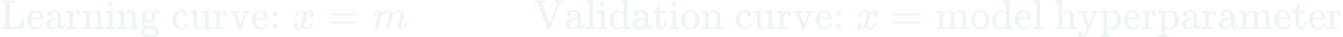</div><ul style="margin:8px 0 10px;padding-right:20px;"><li style="margin:3px 0;">در محور افقی <strong>تعداد نمونه‌های آموزش</strong> قرار می‌گیرد، نه شمارهٔ Epoch یا درجهٔ چندجمله‌ای.</li><li style="margin:3px 0;">در محور عمودی خطای Train و Validation را <strong>با یک معیار یکسان</strong> مانند RMSE رسم می‌کنیم.</li><li style="margin:3px 0;">کم‌بودن خطای Train به‌تنهایی نشانهٔ بهتر بودن مدل نیست؛ باید منحنی Validation را هم ببینیم.</li><li style="margin:3px 0;">Test نهایی در هیچ‌یک از این نمودارها برای انتخاب مدل استفاده نمی‌شود.</li></ul></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #268cbb;border-radius:12px;background:rgba(38,140,187,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#268cbb;border-radius:50%;margin-left:8px;"></span>ریاضیات Learning Curves | در هر نقطه دقیقاً چه حساب می‌کنیم؟</div><p style="margin:7px 0 11px;">فرض کن در یکی از Foldها از بخش آموزشی، زیرمجموعه‌ای با اندازهٔ <code>m</code> انتخاب می‌کنیم. مدل را <strong>فقط روی همین m نمونه</strong> Fit می‌کنیم. سپس RMSE را یک‌بار روی همان زیرمجموعه و یک‌بار روی بخش Validation آن Fold محاسبه می‌کنیم.</p><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;margin:12px 0;padding:13px 8px;border-radius:9px;background:rgba(148,163,184,.055);border:1px solid rgba(148,163,184,.20);">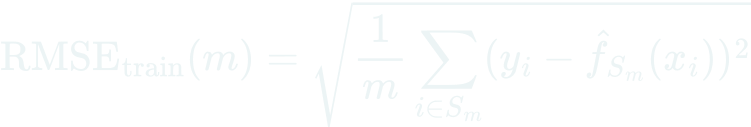</div><p style="margin:7px 0 11px;">اگر این کار را برای هر <code>m</code> و هر یک از <code>K</code> فولد تکرار کنیم، خطای اعتبارسنجیِ میانگین برابر رابطهٔ زیر می‌شود:</p><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;margin:12px 0;padding:13px 8px;border-radius:9px;background:rgba(148,163,184,.055);border:1px solid rgba(148,163,184,.20);">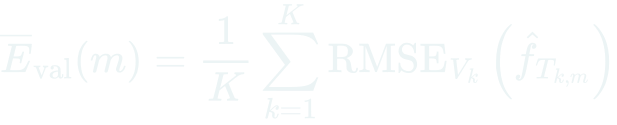</div><p style="margin:7px 0 11px;">توجه: اندازهٔ <code>m</code> در <code>learning_curve</code> معمولاً نسبتی از <strong>بخش آموزشی هر Fold</strong> است، نه از کل داده‌ها. یعنی اگر ۶۰ نمونه و ۵-Fold داریم، بزرگ‌ترین مجموعهٔ آموزشی در هر دور ۴۸ نمونه دارد.</p><p style="margin:7px 0 11px;">میانگین و انحراف معیار نمره‌های فولدها اطلاعات مفیدی دارند، اما پراکندگی چند Fold به‌تنهایی یک بازهٔ اطمینان آماری رسمی محسوب نمی‌شود.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #268cbb;border-radius:12px;background:rgba(38,140,187,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#268cbb;border-radius:50%;margin-left:8px;"></span>نمایش عملی | Learning Curves برای مدل ساده و مدل پیچیده</div><p style="margin:7px 0 11px;">کد بعدی روی همان دادهٔ توسعهٔ هفتهٔ ۱۲ اجرا می‌شود. درجهٔ ۱ و ۸ را مقایسه می‌کنیم و هر منحنی از میانگین خطا روی ۵ Fold به دست می‌آید. بخش رنگی کم‌رنگ اطراف منحنی، <strong>یک انحراف معیار فولدها</strong> است، نه تضمین احتمالاتی.</p><p style="margin:7px 0 11px;">پیش‌پردازش داخل <code>make_poly_model</code> قرار دارد و در هر برازش از نو بر دادهٔ آموزشی همان Fold یاد گرفته می‌شود.</p></div>

In [ ]:
from sklearn.model_selection import learning_curve

# Keep the sealed test set completely outside learning-curve calculations.
learning_cv = KFold(n_splits=5, shuffle=True, random_state=123)
learning_sizes = np.array([0.40, 0.55, 0.70, 0.85, 1.00])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=False)
learning_results = {}

for ax, degree in zip(axes, [1, 8]):
    sizes, train_scores, validation_scores = learning_curve(
        estimator=make_poly_model(degree),
        X=X_trainval, y=y_trainval,
        train_sizes=learning_sizes,
        cv=learning_cv,
        scoring="neg_root_mean_squared_error",
        shuffle=True, random_state=7,
        n_jobs=1,
    )
    train_rmse = -train_scores
    validation_rmse = -validation_scores
    learning_results[degree] = (sizes, train_rmse, validation_rmse)

    for data, label in [(train_rmse, "Train RMSE"),
                        (validation_rmse, "Validation RMSE")]:
        average = data.mean(axis=1)
        spread = data.std(axis=1, ddof=0)
        line, = ax.plot(sizes, average, marker="o", label=label)
        ax.fill_between(sizes, np.maximum(0, average - spread),
                        average + spread, color=line.get_color(), alpha=0.15)

    ax.set_title(f"Learning curve | polynomial degree {degree}")
    ax.set_xlabel("Number of training samples per fold")
    ax.set_ylabel("RMSE (lower is better)")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()
print("Training sizes:", learning_results[1][0])
print("Fold-score matrix shape:", learning_results[1][1].shape)

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #1f9b86;border-radius:12px;background:rgba(31,155,134,.085);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#1f9b86;border-radius:50%;margin-left:8px;"></span>فعالیت مستقل | ساخت Learning Curve از صفر</div><p style="margin:7px 0 11px;">این بار از <code>sklearn.model_selection.learning_curve</code> استفاده نکن. با <code>KFold</code> یا حتی اندیس‌سازی NumPy، برای درجات ۱ و ۸ و چهار اندازهٔ آموزش، خودش از ابتدا حلقه‌ها، Fit هر Fold، محاسبهٔ RMSE، میانگین و نمودار را بنویس.</p><ul style="margin:8px 0 10px;padding-right:20px;"><li style="margin:3px 0;">حداقل چهار اندازهٔ <code>0.4, 0.6, 0.8, 1.0</code> نسبت به Train همان Fold.</li><li style="margin:3px 0;">هر پیش‌پردازش را فقط روی زیرمجموعهٔ آموزش همان دور Fit کن؛ Validation و Test وارد آن نشوند.</li><li style="margin:3px 0;">جدول خروجی شامل تعداد داده، میانگین RMSE Train، میانگین و انحراف معیار RMSE Validation باشد.</li><li style="margin:3px 0;">در پایان، یک بند توضیح بده کدام درجه احتمالاً با دادهٔ بیشتر بهتر می‌شود و چرا.</li></ul><p style="margin:7px 0 11px;"></p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای فعالیت تکمیلی | Learning Curve از صفر</div><div style="margin:3px 0;"><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">KFold</a><a dir="ltr" href="https://numpy.org/doc/stable/reference/generated/numpy.array_split.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">NumPy array_split</a><a dir="ltr" href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Matplotlib plot</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">از تابع آمادهٔ sklearn.model_selection.learning_curve استفاده نکنید؛ حلقهٔ اندازهٔ داده و Foldها را خودتان بنویسید.</div></div>

In [ ]:
# Write the entire learning-curve implementation independently here.

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #d48b31;border-radius:12px;background:rgba(212,139,49,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#d48b31;border-radius:50%;margin-left:8px;"></span>بخش تکمیلی ۲ | Residual Analysis پیشرفته</div><p style="margin:7px 0 11px;">باقی‌مانده یا Residual، تفاوت مقدار واقعی و پیش‌بینی است. بررسی فقط RMSE کافی نیست: دو مدل با RMSE یکسان ممکن است الگوهای خطای بسیار متفاوت داشته باشند. نمودار باقی‌مانده‌ها کمک می‌کند این الگوها را شناسایی کنیم.</p><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;margin:12px 0;padding:13px 8px;border-radius:9px;background:rgba(148,163,184,.055);border:1px solid rgba(148,163,184,.20);">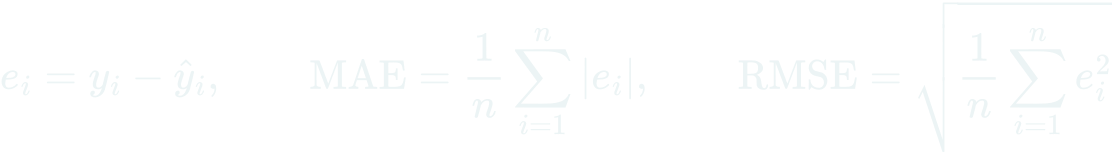</div><ul style="margin:8px 0 10px;padding-right:20px;"><li style="margin:3px 0;"><strong>Residual vs Predicted:</strong> اگر شکل U یا منحنی ببینیم، شاید مدل رابطهٔ غیرخطی را خوب نگرفته باشد.</li><li style="margin:3px 0;"><strong>Residual vs Feature:</strong> اگر با تغییر ویژگی، میانگین یا پراکندگی خطا عوض شود، سرنخ مسئله داریم.</li><li style="margin:3px 0;"><strong>Histogram:</strong> توزیع و چولگی خطا را ببینیم؛ نرمال نبودن آن به‌تنهایی به معنی بی‌فایده‌بودن پیش‌بینی نیست.</li><li style="margin:3px 0;"><strong>گروه‌بندی خطا:</strong> ممکن است میانگین کل خطا نزدیک صفر باشد، ولی خطا در بعضی بازه‌ها بسیار بالا باشد.</li></ul></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #d48b31;border-radius:12px;background:rgba(212,139,49,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#d48b31;border-radius:50%;margin-left:8px;"></span>ریاضیات و دام‌های تفسیر باقی‌مانده‌ها</div><p style="margin:7px 0 11px;">اگر مدلِ داده‌ها به صورت <code>Y = f(X) + ε</code> باشد، با فرض اینکه نویز در هر مقدار X میانگین شرطی صفر داشته باشد، تابع واقعی میانگین شرطی را مدل می‌کند:</p><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;margin:12px 0;padding:13px 8px;border-radius:9px;background:rgba(148,163,184,.055);border:1px solid rgba(148,163,184,.20);">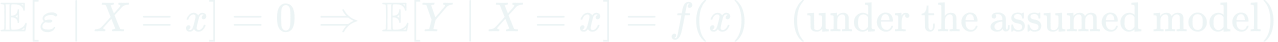</div><p style="margin:7px 0 11px;">اگر واریانس شرطی نویز با X تغییر کند، پدیدهٔ <strong>ناهمسانی واریانس (Heteroscedasticity)</strong> داریم:</p><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;margin:12px 0;padding:13px 8px;border-radius:9px;background:rgba(148,163,184,.055);border:1px solid rgba(148,163,184,.20);">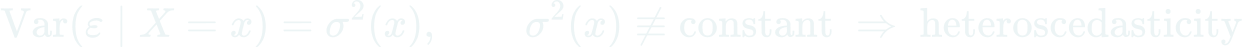</div><p style="margin:7px 0 11px;">در دادهٔ واقعی یک الگوی فن‌مانند از پراکندگی باقی‌مانده‌ها می‌تواند نشانهٔ ناهمسانی واریانس باشد؛ اما یک نمودار کوچک اثبات قطعی نیست. همچنین Residualهای <strong>Train</strong> ممکن است به دلیل Fit شدن مدل روی همان نقاط بیش از حد خوش‌بینانه باشند؛ برای تشخیص تعمیم‌پذیری از Validation یا پیش‌بینی‌های Out-of-Fold استفاده کن.</p><p style="margin:7px 0 11px;">تفاوت <strong>Outlier</strong> (نمونه با خطای بزرگ) و <strong>High Leverage</strong> (نمونه با ورودی غیرمعمول) را به یاد داشته باش؛ یک نمونه ممکن است یکی را داشته باشد و دیگری را نه.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #d48b31;border-radius:12px;background:rgba(212,139,49,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#d48b31;border-radius:50%;margin-left:8px;"></span>نمایش عملی | سه نمودار و تحلیل خطا برحسب بازهٔ ورودی</div><p style="margin:7px 0 11px;">مدل درجهٔ ۵ را فقط روی Train برازش می‌دهیم، سپس در Validation باقی‌مانده‌ها را رسم می‌کنیم. در پایان Validation را برحسب ویژگی ورودی به چهار بازه تقسیم می‌کنیم تا ببینیم خطا در کدام بازه بیشتر است. Test همچنان دست‌نخورده می‌ماند.</p></div>

In [ ]:
# Inspect out-of-sample residuals on validation, not on the sealed test set.
residual_model = make_poly_model(5)
residual_model.fit(X_train, y_train)
val_prediction = residual_model.predict(X_val)
val_residuals = y_val - val_prediction

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(val_prediction, val_residuals, alpha=0.75)
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set(xlabel="Predicted value", ylabel="Residual (actual - predicted)",
            title="Residuals vs predicted")

axes[1].scatter(X_val[:, 0], val_residuals, alpha=0.75)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(xlabel="Input x", ylabel="Residual", title="Residuals vs input")

axes[2].hist(val_residuals, bins=8, edgecolor="black", alpha=0.75)
axes[2].axvline(0, color="gray", linestyle="--")
axes[2].set(xlabel="Residual", ylabel="Frequency", title="Validation residual distribution")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

residual_summary = pd.DataFrame({"x": X_val[:, 0],
                                 "prediction": val_prediction,
                                 "residual": val_residuals})
residual_summary["region"] = pd.cut(residual_summary["x"], bins=4)
region_errors = residual_summary.groupby("region", observed=True).agg(
    count=("residual", "size"),
    mean_residual=("residual", "mean"),
    mean_absolute_residual=("residual", lambda z: np.abs(z).mean()),
)
display(region_errors.round(4))
print("Overall mean residual:", round(val_residuals.mean(), 4))

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #1f9b86;border-radius:12px;background:rgba(31,155,134,.085);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#1f9b86;border-radius:50%;margin-left:8px;"></span>فعالیت مستقل کوتاه | بررسی خطای دو مدل</div><p style="margin:7px 0 11px;">دو مدل چندجمله‌ای درجهٔ ۱ و ۹ بساز، هر دو را فقط روی <code>X_train / y_train</code> آموزش بده و روی <code>X_val / y_val</code> ارزیابی کن. برای هر مدل، <strong>Residual vs Input</strong> را رسم کن و جدول <code>Mean Residual</code> و <code>Validation RMSE</code> بده.</p><p style="margin:7px 0 11px;">در ۳ تا ۵ جمله تحلیل کن آیا از نمودار می‌توان نشانه‌ای از Misspecification یا حساسیت بیش از حد مدل دید. از Test برای تشخیص یا انتخاب مدل استفاده نکن.</p><p style="margin:7px 0 11px;"></p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:8px 0 10px 10px;padding:11px 15px;border:1px solid rgba(14,165,233,.30);border-right:4px solid #0ea5e9;border-radius:11px;background:rgba(14,165,233,.065);direction:rtl;text-align:right;line-height:1.85;color:inherit;"><div style="font-weight:700;margin:0 0 4px;"><span aria-hidden="true" style="color:#38bdf8;margin-left:6px;">◈</span>منابع رسمی برای فعالیت تکمیلی | بررسی باقی‌مانده‌های دو مدل</div><div style="margin:3px 0;"><a dir="ltr" href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Matplotlib scatter</a><a dir="ltr" href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">mean_squared_error</a><a dir="ltr" href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html" style="display:inline-block;direction:ltr;unicode-bidi:isolate;text-decoration:none;border:1px solid rgba(14,165,233,.33);border-radius:7px;background:rgba(14,165,233,.09);padding:5px 9px;margin:3px 0 3px 7px;color:#38bdf8;font-size:.95em;">Pandas DataFrame</a></div><div style="margin-top:5px;font-size:.92em;opacity:.86;">از مدل‌های آموزش‌دیده روی Train برای ارزیابی Validation استفاده کنید؛ تحلیل نمودارها را خودتان بنویسید.</div></div>

In [ ]:
# Build and compare both residual plots from a blank cell.

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #936fd3;border-radius:12px;background:rgba(147,111,211,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#936fd3;border-radius:50%;margin-left:8px;"></span>بخش تکمیلی ۳ | K-Fold، StratifiedKFold و GroupKFold</div><p style="margin:7px 0 11px;">هر سه روش در هر نوبت تعدادی از داده‌ها را برای Validation کنار می‌گذارند، اما <strong>قاعدهٔ ساخت Fold</strong> متفاوت است. انتخاب Splitter باید از جنس داده و هدف ارزیابی بیاید، نه از عادت.</p><ul style="margin:8px 0 10px;padding-right:20px;"><li style="margin:3px 0;"><strong>KFold:</strong> تقسیم عمومی به K بخش؛ مناسب دادهٔ مستقل با توزیع قابل‌قبول، مانند بسیاری از مسائل رگرسیون.</li><li style="margin:3px 0;"><strong>StratifiedKFold:</strong> در مسائل طبقه‌بندی، نسبت کلاس‌های هر Fold را تقریباً حفظ می‌کند؛ برای کلاس‌های نامتوازن مفید است.</li><li style="margin:3px 0;"><strong>GroupKFold:</strong> رکوردهای متعلق به یک گروه، مثل بیمار، کاربر یا مدرسه، نباید هم در Train و هم Validation یک Fold ظاهر شوند؛ GroupKFold این شرط را اعمال می‌کند.</li></ul><p style="margin:7px 0 11px;">برای دادهٔ زمانی این سه روش لزوماً کافی نیستند و روش‌هایی مانند <code>TimeSeriesSplit</code> اهمیت دارند. <strong>StratifiedKFold معمولی را مستقیم برای برچسب هدف پیوستهٔ رگرسیون به‌کار نمی‌بریم.</strong></p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #936fd3;border-radius:12px;background:rgba(147,111,211,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#936fd3;border-radius:50%;margin-left:8px;"></span>دو معیار ریاضی برای انتخاب نوع Fold</div><p style="margin:7px 0 11px;">در StratifiedKFold سهم یک کلاس معین از Validation هر Fold باید تا حد امکان نزدیک سهم آن کلاس در کل داده باشد:</p><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;margin:12px 0;padding:13px 8px;border-radius:9px;background:rgba(148,163,184,.055);border:1px solid rgba(148,163,184,.20);">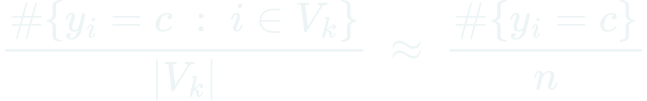</div><p style="margin:7px 0 11px;">در GroupKFold شرط اصلی جلوگیری از اشتراک گروه‌ها میان Train و Validation در هر Fold است:</p><div dir="ltr" style="direction:ltr;text-align:center;max-width:100%;overflow-x:auto;margin:12px 0;padding:13px 8px;border-radius:9px;background:rgba(148,163,184,.055);border:1px solid rgba(148,163,184,.20);">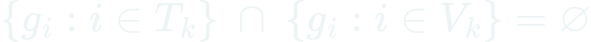</div><p style="margin:7px 0 11px;">از این شرط نمی‌توان نتیجه گرفت نسبت کلاس‌ها در GroupKFold هم همیشه یکسان است. اگر هم وابستگی گروهی داریم و هم توازن کلاس‌ها مهم است، روش‌هایی مانند <code>StratifiedGroupKFold</code> را باید جداگانه بررسی کرد.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #936fd3;border-radius:12px;background:rgba(147,111,211,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#936fd3;border-radius:50%;margin-left:8px;"></span>نمایش کوچک | تفاوت Foldها روی ۲۴ رکورد</div><p style="margin:7px 0 11px;">در مثال بعد هر ۴ رکورد به یک گروه وابسته‌اند. ستون آخر جدول نشان می‌دهد در کدام روش، گروه‌های مشترک در Train و Validation یک Fold دیده می‌شوند. ستون نسبت کلاس ۱ نیز نشان می‌دهد StratifiedKFold چگونه توازن نسبی کلاس را بهتر حفظ می‌کند.</p></div>

In [ ]:
from sklearn.model_selection import StratifiedKFold, GroupKFold

# Each record is one observation; four observations share one group.
n_obs = 24
example_X = np.arange(n_obs).reshape(-1, 1)
example_groups = np.repeat(np.arange(6), 4)
example_labels = np.array([0] * 15 + [1] * 9)
np.random.default_rng(17).shuffle(example_labels)

splitters = {
    "KFold": KFold(n_splits=4, shuffle=True, random_state=10),
    "StratifiedKFold": StratifiedKFold(n_splits=4, shuffle=True, random_state=10),
    "GroupKFold": GroupKFold(n_splits=4),
}

split_comparison = []
for name, splitter in splitters.items():
    if name == "GroupKFold":
        splits = splitter.split(example_X, example_labels, groups=example_groups)
    elif name == "StratifiedKFold":
        splits = splitter.split(example_X, example_labels)
    else:
        splits = splitter.split(example_X)

    for fold_number, (train_idx, val_idx) in enumerate(splits, start=1):
        overlap = set(example_groups[train_idx]) & set(example_groups[val_idx])
        split_comparison.append({
            "Splitter": name, "Fold": fold_number,
            "Train size": len(train_idx), "Validation size": len(val_idx),
            "Validation class-1 fraction": example_labels[val_idx].mean(),
            "Group overlap count": len(overlap),
        })

display(pd.DataFrame(split_comparison).round(3))
assert all(row["Group overlap count"] == 0 for row in split_comparison
           if row["Splitter"] == "GroupKFold")

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 15px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.34);border-right:5px solid #6875d9;border-radius:12px;background:rgba(104,117,217,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.06;color:inherit;"><div style="font-weight:750;font-size:1.14em;margin:0 0 10px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#6875d9;border-radius:50%;margin-left:8px;"></span>جمع‌بندی و سؤال‌های مفهومی این پیوست</div><ul style="margin:8px 0 10px;padding-right:20px;"><li style="margin:3px 0;">اگر خطای Train پایین باشد اما Validation بالا بماند، Learning Curve چه اطلاعات اضافه‌ای دربارهٔ اثر افزایش داده به ما می‌دهد؟</li><li style="margin:3px 0;">چرا نمودار Residual vs Feature ممکن است مسئله‌ای نشان بدهد که RMSE تنها پنهان کرده است؟</li><li style="margin:3px 0;">برای دادهٔ چند ویزیت از یک بیمار، چرا KFold معمولی می‌تواند ارزیابی را بیش از حد خوش‌بینانه کند؟</li></ul></div>